# Audio Computing - Lab 3: Reverberation and 3D Audio

In this lab we will get some experience in simulating rooms and 3D audio. For reverb, we will design some simple reverbs using small filters and then work towards a more principled room simulator. You can use whichever sound you like for the following examples, usually a sound with sharp onsets is good for such experiments. One good example is the drum loop [ https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1 ]

In [1]:
# Load a remote WAVE file given its URL, and return the sample rate and waveform
def wavreadurl( url):
    import urllib.request, io, scipy.io.wavfile
    f = urllib.request.urlopen( urllib.request.Request( url))
    sr,s = scipy.io.wavfile.read( io.BytesIO( f.read()))
    return sr, s.astype( 'float32')/32768

# Make a sound player function that plays array "x" with a sample rate "rate", and labels it with "label"
def sound( x, rate=8000, label=''):
    from IPython.display import display, Audio, HTML
    display( HTML( 
    '<style> table, th, td {border: 0px; }</style> <table><tr><td>' + label + 
    '</td><td>' + Audio( x, rate=rate)._repr_html_()[3:] + '</td></tr></table>'
    ))

# Import graphics
from matplotlib.pylab import xlabel, ylabel, title, stem, subplot, pcolormesh, plot, semilogy, legend

sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound( s, sr)

,Your browser does not support the audio element.


## Part 1. Designing simple reverb using filters

The simplest forms of reverbs can be designed using simple delays, comb and allpass filters. We will design one of each to get started.

a) A room with a single wall. For this reverb we will assume that we have a room that only has one reflective wall as shown below. Design a filter that simulates what the microphone will record. Figure out the right filter in the case where $d_i = [0.2, 1]$ meters, and in the case where $d_i = [2, 10]$ meters. Let me know what the differences between these sounds are. To keep things simple, round the delays to an integer number and make up an approximate gain loss due to propagation and the wall bounce. Make sure to plot the resulting filters and their frequency responses, as well as to render the test sound with these two reverbs applied on it.

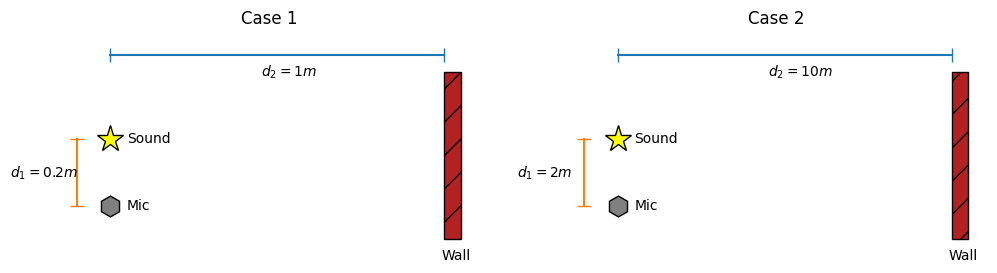

In [2]:
# Run this cell to see a representation of the situation to model
from matplotlib.pylab import gca, gcf, figure
from matplotlib.patches import Rectangle

figure( figsize=(12,3), facecolor='w')
gcf().add_subplot( 1, 2, 1, title='Case 1', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, .2, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.45,.45], marker='|', markersize=10)
gca().plot( [-.1,-.1], [0,.2], marker='_', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .5, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,0,-.35,.4,.94], [0,.2,.1,.4,-.15], ['Mic','Sound','$d_1=0.2m$', '$d_2=1m$', 'Wall'])]
gca().axis( 'equal')

gcf().add_subplot( 1, 2, 2, title='Case 2', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, .2, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.45,.45], marker='|', markersize=10)
gca().plot( [-.1,-.1], [0,.2], marker='_', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .5, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,0,-.35,.4,.94], [0,.2,.1,.4,-.15], ['Mic','Sound','$d_1=2m$', '$d_2=10m$', 'Wall'])]
gca().axis( 'equal');

In [2]:
#hilfsfunktionen
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

def get_impulse_response(b, a, length):
    impulse = np.zeros(length)
    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    return h


def plot_impulse_response(title, fs, h, style="stem"):
    if h.ndim == 1: #wenn mono (1d), eine kanaldimension hinzufügen
        h = h[:, None]

    t = np.arange(len(h)) / fs

    plt.figure(figsize=(10, 4))

    if style == "stem":

        if h.shape[1] == 1:
            plt.vlines(t, 0, h)

            plt.plot(t, h[:, 0], "o", markersize=3)

        elif h.shape[1] == 2:
            plt.vlines(t, 0, h[:, 0])
            plt.plot(t, h[:, 0], "o", markersize=4, label="Left")


            plt.vlines(t, 0, h[:, 1], color="C1")
            plt.plot(t, h[:, 1], "o", markersize=4, label="Right")

            plt.legend()

    elif style == "line":
        if h.shape[1] == 1:
            plt.plot(t, h[:, 0], "o-", markersize=4)

        elif h.shape[1] == 2:
            plt.plot(t, h[:, 0], "o-", markersize=4, label="Left")
            plt.plot(t, h[:, 1], "o--", markersize=4, label="Right")

            plt.legend()
    
    plt.title(title)
    plt.xlabel("Time [s]")
    plt.ylabel("Amplitude")
    
    plt.grid(True)
    plt.show()



def plot_filter_response(title, fs, b, a=1, auto_scale=True, min_db=-20, max_db=20, max_freq=None, worN=2**15):
    fig, (ax0, ax1) = plt.subplots(2, 1, sharex=True)
    
    fig.suptitle(title)

    f, H = signal.freqz(b, a, worN=worN, fs=fs) #genug punkte, damit auch dicht liegende kammspitzen sichtbar sind

    H_dB = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
    ax0.plot(f, H_dB)
    ax0.set_title("Magnitude response")
    ax0.set_ylabel("Magnitude [dB]")
    if not auto_scale:
        ax0.set_ylim(min_db, max_db)
    ax0.grid(True)

    H_ph = np.angle(H)
    ax1.plot(f, H_ph)
    ax1.set_title("Phase response")
    ax1.set_ylabel("Phase")
    ax1.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax1.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])

    ax1.set_xlabel("Frequency [Hz]")
    ax1.grid(True)

    if max_freq is not None:
        ax1.set_xlim(0, max_freq)



def plot_filter_response_from_transfer_function(f, H, title, auto_scale=True, min_db=-20, max_db=20, max_freq=None):
    fig, (ax0, ax1) = plt.subplots(2, 1, sharex=True)
    fig.suptitle(title)

    H_dB = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
    ax0.plot(f, H_dB)
    if not auto_scale:
        ax0.set_ylim(min_db, max_db)
    ax0.set_title("Magnitude response")
    ax0.set_ylabel("Magnitude [dB]")
    ax0.grid(True)

    H_ph = np.angle(H)
    ax1.plot(f, H_ph)
    ax1.set_title("Phase response")
    ax1.set_ylabel("Phase")
    ax1.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax1.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])

    ax1.set_xlabel("Frequency [Hz]")
    ax1.grid(True)

    if max_freq is not None:
        ax1.set_xlim(0, max_freq)

Original sound,Your browser does not support the audio element.


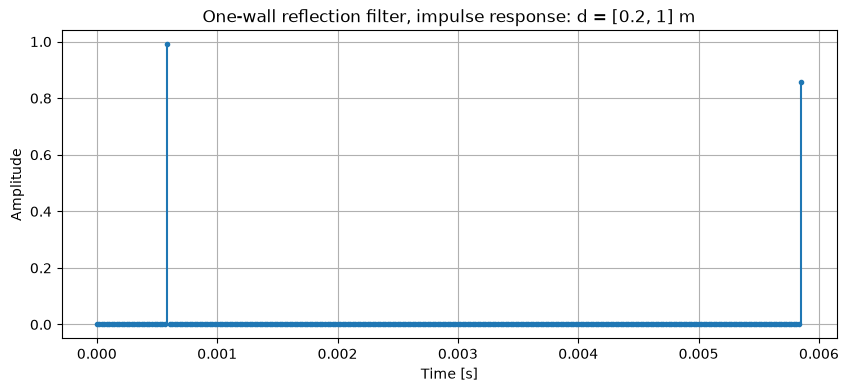

One-wall reflection filter,Your browser does not support the audio element.


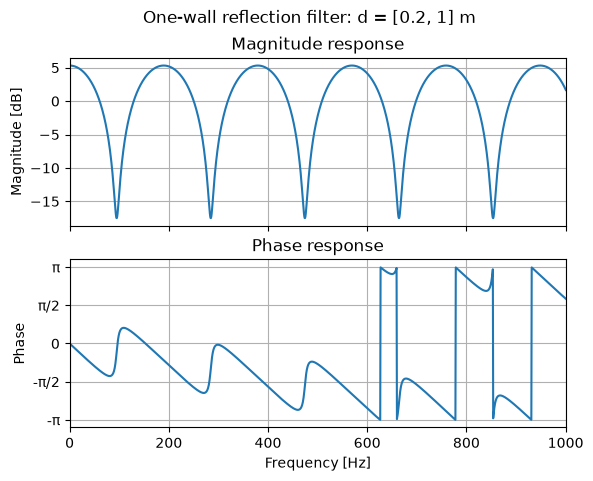

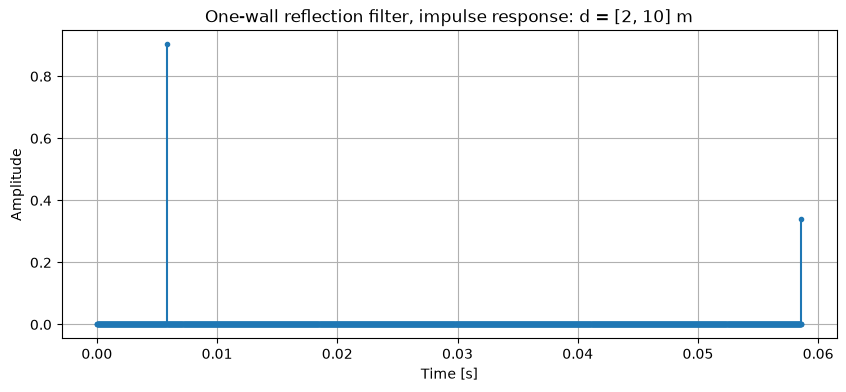

One-wall reflection filter,Your browser does not support the audio element.


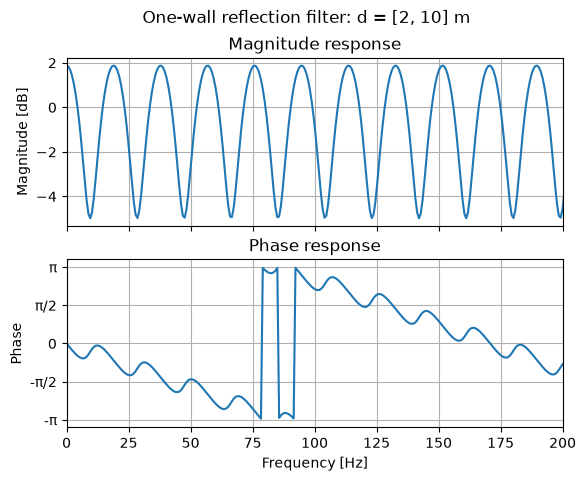

In [4]:
sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")


def one_wall_reflection_filter(sr, d_direct, d_wall, distance_retention=0.95, wall_reflection=0.95, c=343):
    c_sample = c / sr #schallgeschwindigkeit in metern pro sample

    #direkte quelle -> wand -> mikrofon mit spiegelquellen-berechnung
    d_reflection = np.sqrt((2 * d_wall)**2 + d_direct**2)

    delay_direct_samples = int(round(d_direct / c_sample))
    delay_reflection_samples = int(round(d_reflection / c_sample))

    #länge des filters ist die länge der längsten verzögerung
    h = np.zeros(delay_reflection_samples + 1)

    #ungefähre abschwächung durch die entfernung
    h[delay_direct_samples] = distance_retention ** d_direct

    #abschwächung durch die entfernung + reflexionsverlust
    h[delay_reflection_samples] = wall_reflection * distance_retention ** d_reflection

    return h


h_close = one_wall_reflection_filter(sr, 0.2, 1)
plot_impulse_response("One-wall reflection filter, impulse response: d = [0.2, 1] m", sr, h_close)
plot_filter_response("One-wall reflection filter: d = [0.2, 1] m", sr, h_close, max_freq=1000)
output_close = np.convolve(s, h_close)
sound(output_close, sr, "One-wall reflection filter")

#diese verzögerung lässt das audio etwas metallisch und resonant klingen, 
#ich glaube, das liegt daran, dass die verzögerung so kurz ist, dass sie mit der eigentlichen wellenform interferiert

h_far = one_wall_reflection_filter(sr, 2, 10)
plot_impulse_response("One-wall reflection filter, impulse response: d = [2, 10] m", sr, h_far)
plot_filter_response("One-wall reflection filter: d = [2, 10] m", sr, h_far, max_freq=200)
output_far = np.convolve(s, h_far)
sound(output_far, sr, "One-wall reflection filter")

#diese verzögerung ist länger, also bekommen wir keine interferenz, 
#sondern wir hören die verzögerung eher als ein dezentes echo



b) Now we will use a room geometry as shown below. Design the proper filter again, for $d = 1$ meters and then for $d = 10$ meters. Comment on the audible differences between these two settings.

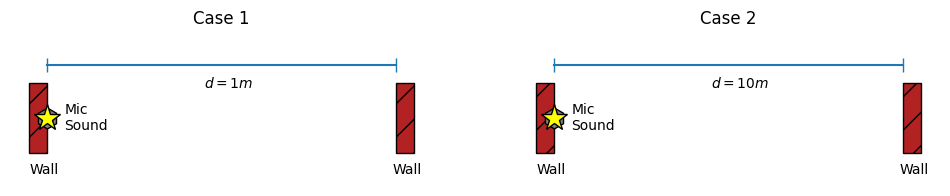

In [5]:
# Run this cell to see a representation of the situation to model
figure( figsize=(12,2), facecolor='w')
gcf().add_subplot( 1, 2, 1, title='Case 1', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, 0, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.15,.15], marker='|', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
gca().add_patch( Rectangle( (0,-.1), -.05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,.4,.94,-.1], [0,.1,-.15,-.15], ['Mic\nSound','$d=1m$','Wall','Wall'])]
gca().axis( 'equal')

gcf().add_subplot( 1, 2, 2, title='Case 2', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, 0, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.15,.15], marker='|', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
gca().add_patch( Rectangle( (0,-.1), -.05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,.4,.94,-.1], [0,.1,-.15,-.15], ['Mic\nSound','$d=10m$','Wall','Wall'])]
gca().axis( 'equal');

Original sound,Your browser does not support the audio element.


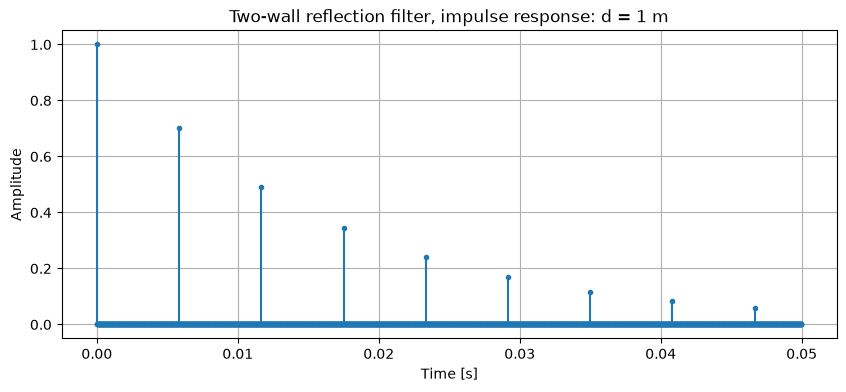

Two-wall reflection filter,Your browser does not support the audio element.


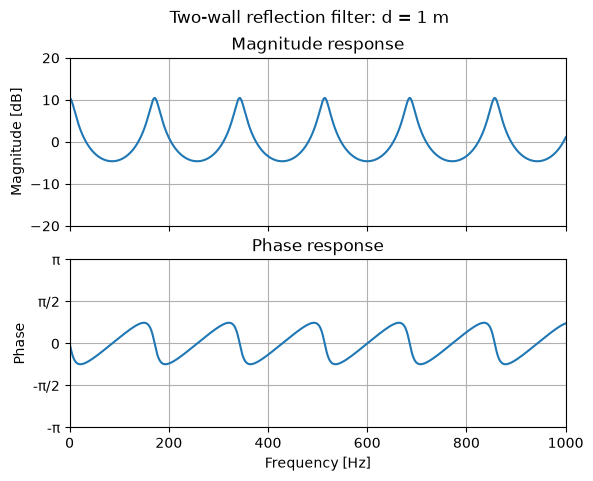

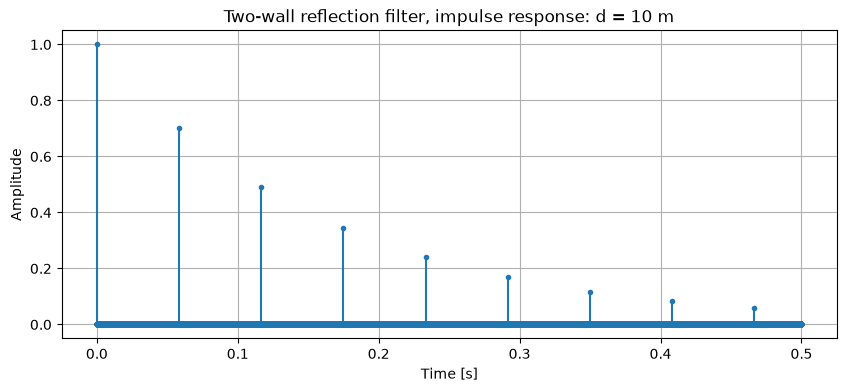

Two-wall reflection filter,Your browser does not support the audio element.


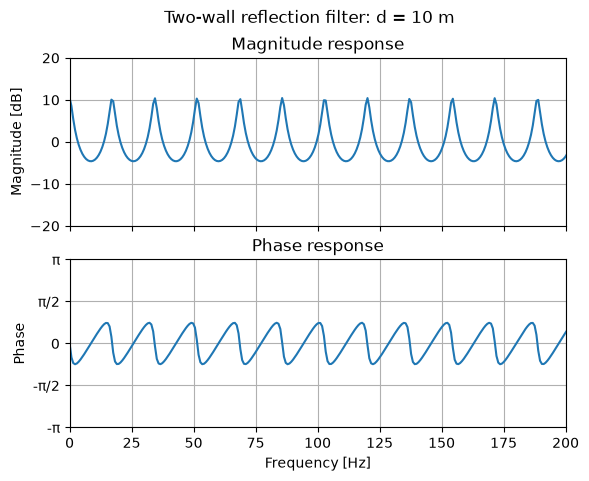

In [6]:
sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")

def two_wall_reflection_filter(sr, d_wall, g=0.7, c=343):
    c_sample = c / sr #schallgeschwindigkeit in metern pro sample

    N = int(round(2 * d_wall / c_sample)) #verzögerung für einen hin- und rückweg

    b = np.zeros(N + 1)
    a = np.zeros(N + 1)

    #y[n] = x[n] + g*y[n-N]
    b[0] = 1

    a[0] = 1
    a[N] = -g

    return b, a


b_close, a_close = two_wall_reflection_filter(sr, 1)
h_close = get_impulse_response(b_close, a_close, int(0.05 * sr))
plot_impulse_response("Two-wall reflection filter, impulse response: d = 1 m", sr, h_close)
plot_filter_response("Two-wall reflection filter: d = 1 m", sr, b_close, a_close, auto_scale=False, max_freq=1000)
output_close = signal.lfilter(b_close, a_close, s)
sound(output_close, sr, "Two-wall reflection filter")

b_far, a_far = two_wall_reflection_filter(sr, 10)
h_far = get_impulse_response(b_far, a_far, int(0.5 * sr))
plot_impulse_response("Two-wall reflection filter, impulse response: d = 10 m", sr, h_far)
plot_filter_response("Two-wall reflection filter: d = 10 m", sr, b_far, a_far, auto_scale=False, max_freq=200)
output_far = signal.lfilter(b_far, a_far, s)
sound(output_far, sr, "Two-wall reflection filter")

#hier bekommen wir ähnliche ergebnisse wie mit dem ein-wand-filter, nur dass die echos 
#unendlich sind, da es ein iir ist. der nahe filter klingt etwas metallischer und resonanter 
#und der ferne filter hat einen schweif aus hörbaren echos, die dem originalklang folgen.


c) Since for small values of $d$ the output above gets its spectrum altered, we will use an allpass filter to make a more natural sounding echo pattern. Use the formulation shown in the lecture slides and compare that filter’s frequency response with the response from the filter in the section b) above.

Original sound,Your browser does not support the audio element.


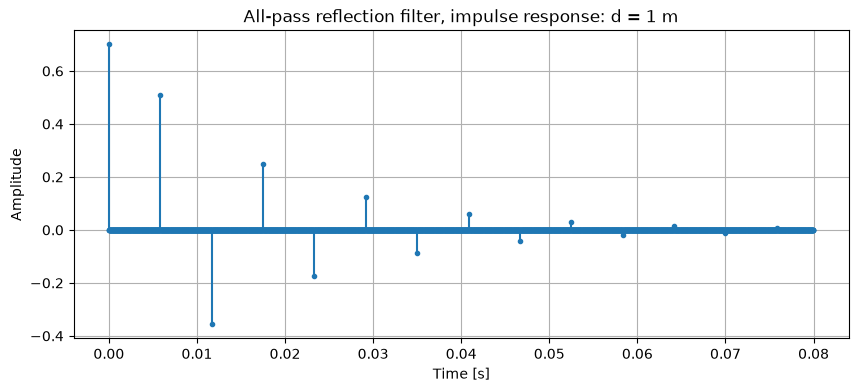

All-pass reflection filter,Your browser does not support the audio element.


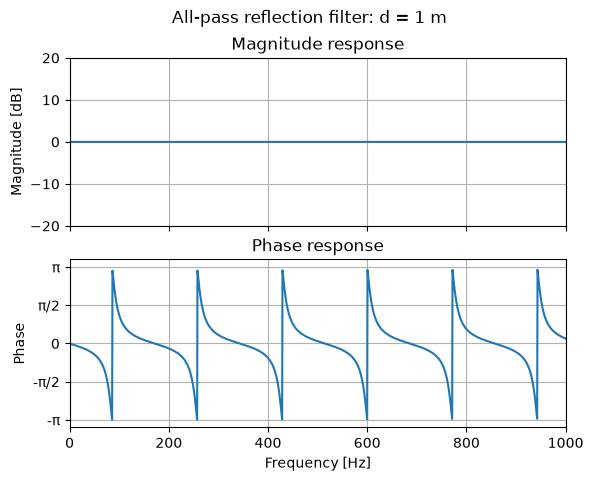

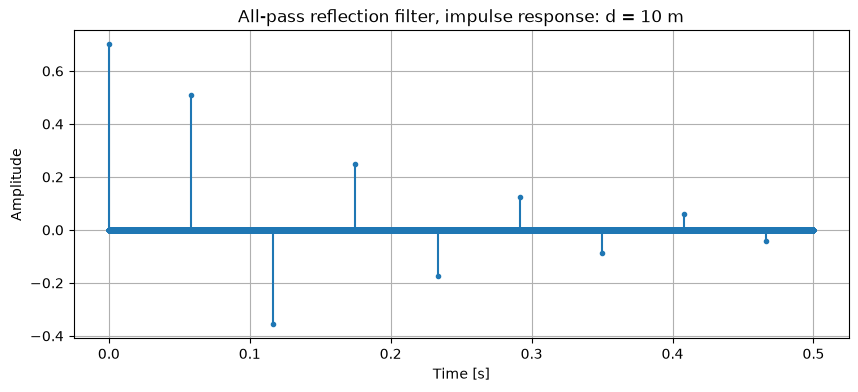

All-pass reflection filter,Your browser does not support the audio element.


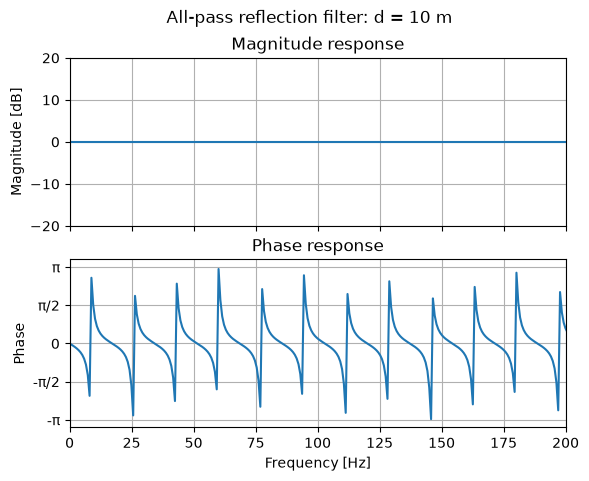

In [7]:
sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")


def allpass_reflection_filter(sr, d_wall, g=0.7, c=343):
    c_sample = c / sr #schallgeschwindigkeit in metern pro sample

    N = int(round(2 * d_wall / c_sample)) #verzögerung für einen hin- und rückweg

    b = np.zeros(N + 1)
    a = np.zeros(N + 1)

    #y[n] = g*x[n] + x[n-N] - g*y[n-N]
    b[0] = g
    b[N] = 1

    a[0] = 1
    a[N] = g

    return b, a


b_close, a_close = allpass_reflection_filter(sr, 1)
h_close = get_impulse_response(b_close, a_close, int(0.08 * sr))
plot_impulse_response("All-pass reflection filter, impulse response: d = 1 m", sr, h_close)
plot_filter_response("All-pass reflection filter: d = 1 m", sr, b_close, a_close, auto_scale=False, max_freq=1000)
output_close = signal.lfilter(b_close, a_close, s)
sound(output_close, sr, "All-pass reflection filter")

b_far, a_far = allpass_reflection_filter(sr, 10)
h_far = get_impulse_response(b_far, a_far, int(0.5 * sr))
plot_impulse_response("All-pass reflection filter, impulse response: d = 10 m", sr, h_far)
plot_filter_response("All-pass reflection filter: d = 10 m", sr, b_far, a_far, auto_scale=False, max_freq=200)
output_far = signal.lfilter(b_far, a_far, s)
sound(output_far, sr, "All-pass reflection filter")

#die betragsgänge sind komplett flach, was sie beim zwei-wand-filter nicht waren
#allerdings gibt es beim nahen filter immer noch einen leicht metallischen klang, hörbar in den höheren frequenzen
#und die verzögerungszeit beim fernen filter ist immer noch so lang, dass sie als getrennte echos gehört werden


## Part 2. Schroeder reverberators

Now we will combine multiple filters to make a more serious sounding reverb. Implement the structure shown in slide 26 of the reverb lecture (the slide is titled "*Wetness of reverb*").

Try to find the necessary parameters for the above structure that makes it sound as good as possible (not too busy, not too subtle). Hint: There is no right answer! Try a few things, see what sounds best and explain why you used the parameters you decided to use. As you come across some bad sounding cases, describe what the problem was. As always show us nice plots that show what you've done, and make sure you render the sound outputs too.

dry,Your browser does not support the audio element.


Small room,Your browser does not support the audio element.


Small room with harmonically related distances,Your browser does not support the audio element.


Small room but with worse all-pass diffusion,Your browser does not support the audio element.


Very big room with long all-pass delays,Your browser does not support the audio element.


Very big room with short all-pass delays,Your browser does not support the audio element.


... (4 outputs left out)

Very big room with long all-pass delays: rt60 = 1.18 s


Very big room with short all-pass delays: rt60 = 1.22 s


Very big room with medium all-pass delays: rt60 = 1.20 s


Big room, pretty ok sounding: rt60 = 0.93 s


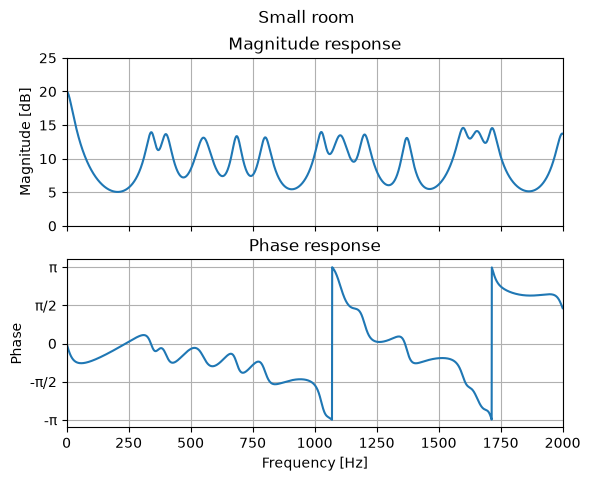

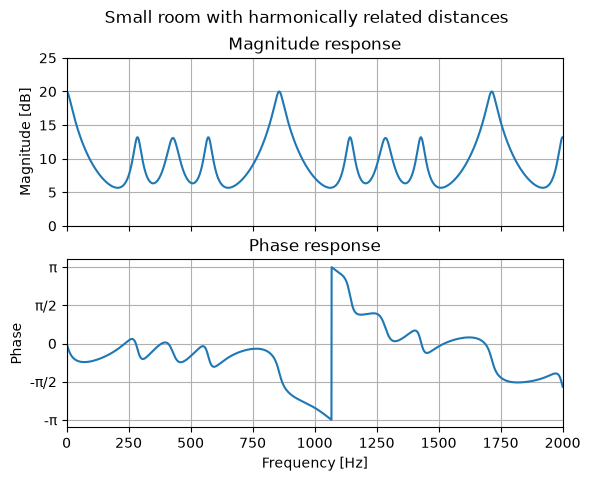

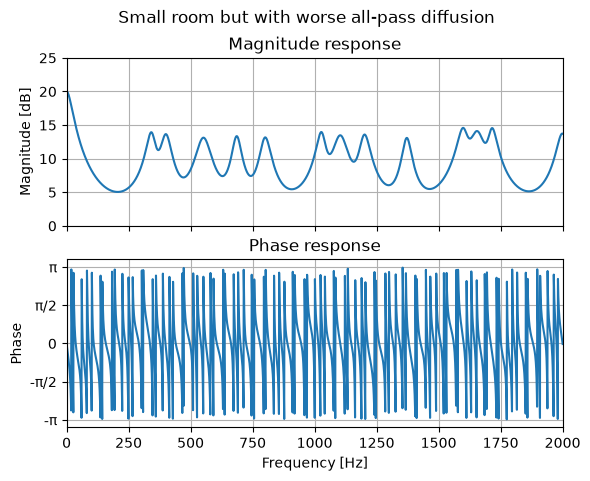

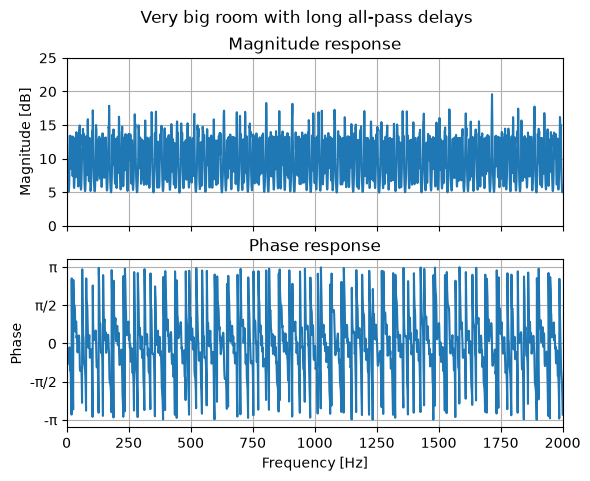

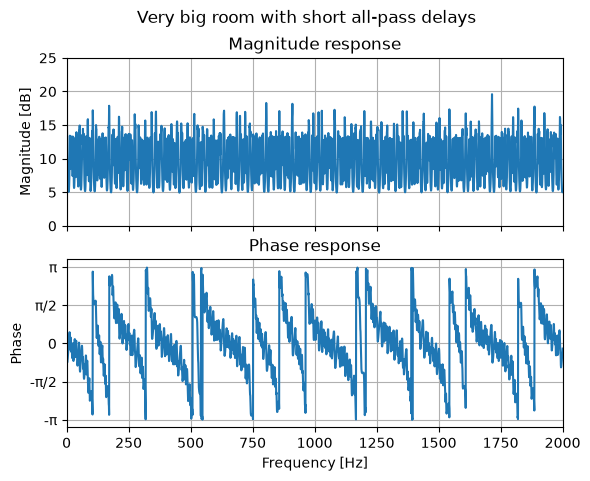

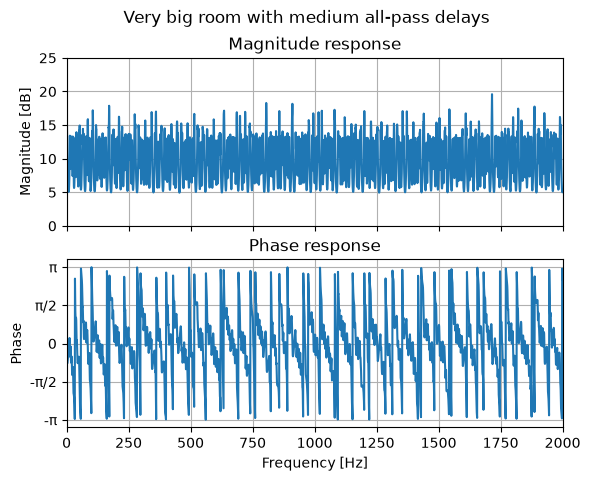

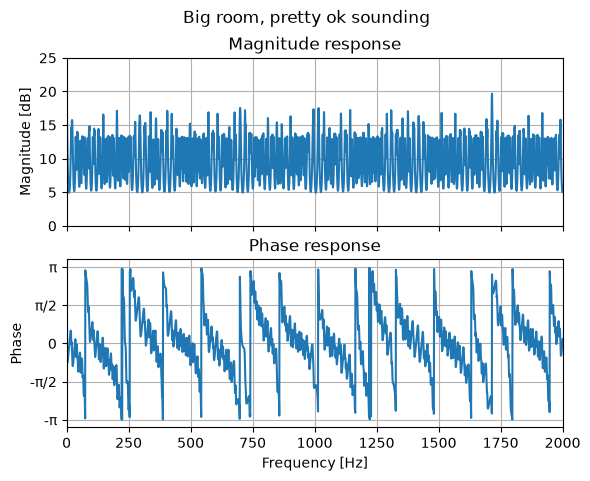

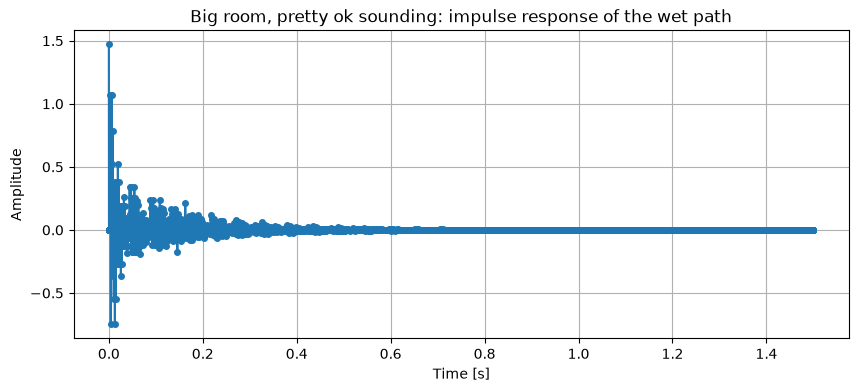

In [8]:
sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

dry = s
sound(dry, sr, "dry")

def schroeder_reverberator(s, sr, d_comb1, d_comb2, d_comb3, d_allpass1, d_allpass2):
    #drei kammfilter parallel
    b_comb1, a_comb1 = two_wall_reflection_filter(sr, d_comb1)
    b_comb2, a_comb2 = two_wall_reflection_filter(sr, d_comb2)
    b_comb3, a_comb3 = two_wall_reflection_filter(sr, d_comb3)

    comb_output_1 = signal.lfilter(b_comb1, a_comb1, s)
    comb_output_2 = signal.lfilter(b_comb2, a_comb2, s)
    comb_output_3 = signal.lfilter(b_comb3, a_comb3, s)

    comb_mix = comb_output_1 + comb_output_2 + comb_output_3

    #zwei allpassfilter in reihe
    b_allpass1, a_allpass1 = allpass_reflection_filter(sr, d_allpass1)
    b_allpass2, a_allpass2 = allpass_reflection_filter(sr, d_allpass2)

    allpass_1 = signal.lfilter(b_allpass1, a_allpass1, comb_mix)
    wet = signal.lfilter(b_allpass2, a_allpass2, allpass_1)

    f, H_comb1 = signal.freqz(b_comb1, a_comb1, worN=2**15, fs=sr)
    _, H_comb2 = signal.freqz(b_comb2, a_comb2, worN=2**15, fs=sr)
    _, H_comb3 = signal.freqz(b_comb3, a_comb3, worN=2**15, fs=sr)

    _, H_allpass1 = signal.freqz(b_allpass1, a_allpass1, worN=2**15, fs=sr)
    _, H_allpass2 = signal.freqz(b_allpass2, a_allpass2, worN=2**15, fs=sr)

    H_comb = H_comb1 + H_comb2 + H_comb3
    H_total = H_comb * H_allpass1 * H_allpass2

    return wet, f, H_total

min_db = 0
max_db = 25

#ohne skalierung ist die nasse spur ~11 db lauter als die trockene (drei kammfilter werden addiert,
#jeder mit bis zu 1/(1-g) verstärkung), dann klingt alles nur nach hall.
#deshalb wird die nasse spur auf den pegel der trockenen normiert und mit wet_gain gemischt
wet_gain = 0.5 #-6 db unter dem trockenen signal

def mix_dry_wet(dry, wet, wet_gain):
    return dry + wet_gain * wet * np.std(dry) / np.std(wet)

#dieser modelliert einen kleinen raum ziemlich gut, würde ich sagen
wet, f, H = schroeder_reverberator(s, sr, 0.31, 0.43, 0.5, 0.05, 0.08)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Small room")
plot_filter_response_from_transfer_function(f, H, "Small room", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)

#kleiner raum mit harmonisch verwandten abständen, man kann die resonanzen wirklich hören
#dieser hat den einzigartigsten frequenzgang von allen filtern, die ich hier ausprobiere
#die resonanzen sind auch visuell offensichtlich
wet, f, H = schroeder_reverberator(s, sr, 0.2, 0.4, 0.6, 0.04, 0.08)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Small room with harmonically related distances")
plot_filter_response_from_transfer_function(f, H, "Small room with harmonically related distances", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)

#ich habe gelesen, dass die kammfilter in schroeder-hallgeräten normalerweise längere verzögerungen haben als die 
#allpassfilter, weshalb ich das bei den vorherigen beispielen standardmäßig so gemacht habe, aber hier habe ich versucht,
#es zu ändern, und es klingt nicht toll. so wie ich es verstehe, sind die allpassfilter
#dazu da, die echos zu zerstreuen, und die kammfilter, um einen nachhallschweif zu erzeugen.
#hier erzeugen die kurzen kammverzögerungen einen sehr metallischen klang, und die zerstreuung der allpassfilter
#wird weiter auseinandergezogen und ist nicht so effizient.
wet, f, H = schroeder_reverberator(s, sr, 0.31, 0.43, 0.5, 3.1, 4.2)
plot_filter_response_from_transfer_function(f, H, "Small room but with worse all-pass diffusion", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Small room but with worse all-pass diffusion")

#bei diesem höre ich ein metallisches klingeln
wet, f, H = schroeder_reverberator(s, sr, 8.1, 10.0, 13.0, 3.3, 4.1)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Very big room with long all-pass delays")
plot_filter_response_from_transfer_function(f, H, "Very big room with long all-pass delays", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)

#bei diesem höre ich deutliche echos
#vielleicht müssen die kurzen allpass-verzögerungen bei so langen kammverzögerungen etwas länger sein, 
#damit sie die lücken zwischen den kammverzögerungen tatsächlich füllen
wet, f, H = schroeder_reverberator(s, sr, 8.1, 10.0, 13.0, 0.5, 0.8)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Very big room with short all-pass delays")
plot_filter_response_from_transfer_function(f, H, "Very big room with short all-pass delays", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)

#das scheint ein ziemlich guter kompromiss aus den beiden vorherigen für einen sehr großen raum zu sein
#es könnte definitiv noch etwas feinabstimmung gebrauchen, aber ich lasse diesen hier
#nur um die tendenz zu zeigen
wet, f, H = schroeder_reverberator(s, sr, 8.1, 10.0, 13.0, 1.5, 2.6)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Very big room with medium all-pass delays")
plot_filter_response_from_transfer_function(f, H, "Very big room with medium all-pass delays", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)

#den raum etwas kleiner gemacht, um zu sehen, ob das hilft, ich finde, es klingt ziemlich ok
wet, f, H = schroeder_reverberator(s, sr, 7.6, 8.1, 9.3, 0.35, 1.1)
mix = mix_dry_wet(dry, wet, wet_gain)
sound(mix, sr, "Big room, pretty ok sounding")
plot_filter_response_from_transfer_function(f, H, "Big room, pretty ok sounding", auto_scale=False, min_db=min_db, max_db=max_db, max_freq=2000)


#um also generell einen gut klingenden hall zu bekommen, fand ich es gut, harmonisch verwandte 
#abstände zu vermeiden und auch die allpass-verzögerungen so anzupassen, dass sie die kammverzögerungen passend zerstreuen - immer 
#kürzer, aber skaliert danach, wie lang die kammverzögerungen sind, scheint eine gute faustregel zu sein


#nachhallzeit aus der impulsantwort (schroeder-rückwärtsintegration, t20 auf 60 db hochgerechnet)
def estimate_rt60(h, fs):
    edc = np.cumsum(h[::-1]**2)[::-1]
    edc_dB = 10 * np.log10(edc / edc[0] + 1e-30)
    i5 = np.argmax(edc_dB < -5)
    i25 = np.argmax(edc_dB < -25)
    return 3 * (i25 - i5) / fs

impulse = np.zeros(4 * sr)
impulse[0] = 1
settings = {
    "Small room": (0.31, 0.43, 0.5, 0.05, 0.08),
    "Small room with harmonically related distances": (0.2, 0.4, 0.6, 0.04, 0.08),
    "Small room but with worse all-pass diffusion": (0.31, 0.43, 0.5, 3.1, 4.2),
    "Very big room with long all-pass delays": (8.1, 10.0, 13.0, 3.3, 4.1),
    "Very big room with short all-pass delays": (8.1, 10.0, 13.0, 0.5, 0.8),
    "Very big room with medium all-pass delays": (8.1, 10.0, 13.0, 1.5, 2.6),
    "Big room, pretty ok sounding": (7.6, 8.1, 9.3, 0.35, 1.1),
}
for name, params in settings.items():
    h, _, _ = schroeder_reverberator(impulse, sr, *params)
    print(f"{name}: rt60 = {estimate_rt60(h, sr):.2f} s")

h, _, _ = schroeder_reverberator(impulse[:int(1.5 * sr)], sr, *settings["Big room, pretty ok sounding"])
plot_impulse_response("Big room, pretty ok sounding: impulse response of the wet path", sr, h, style="line")

## Part 3. Applying a real room response

To apply a more realistic filter we need to use a real room response. Download the St. Andrew’s church room impulse response (Stereo) from:

[ https://www.space-net.hosted.york.ac.uk/node/53/index.html ]

Make sure that the sound you will convolve with it will be at the same sampling rate. This impulse response captures that church’s RIR using two channels. To synthesize a sound in that room you need to convolve it with the impulse response. If your test sound is a single-channel recording, you can simply convolve it with each of the two impulse responses and then use the resulting outputs as the left and right channel. You will notice that using the ```scipy.signal.lfilter``` command for this operation can take very long to compute. For faster convolutions we need to perform this filtering in the frequency domain (using the fast convolution algorithm that we mentioned in the filtering lecture). The function ```numpy.convolve``` automatically does that (if you use an up to date version), otherwise you can directly use ```scipy.signal.fftconvolve```.  Verify that the resulting output sounds like it has been placed inside a church.


In [7]:
from scipy.io import wavfile
from scipy import signal

sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

def apply_impulse_response(s, h):
    #mono-impulsantwort
    if h.ndim == 1:
        wet = signal.fftconvolve(s, h)

    #stereo-impulsantwort
    elif h.ndim == 2 and h.shape[1] == 2:
        wet_left = signal.fftconvolve(s, h[:, 0])
        wet_right = signal.fftconvolve(s, h[:, 1])
        wet = np.array([wet_left, wet_right])

    return wet


sr_ir, h = wavfile.read("roomresponse_standrewschurch_48k.wav")
output = apply_impulse_response(s, h)
sound(output, sr)


,Your browser does not support the audio element.


## Part 4. Measuring a room response.

#### This is for grad student credit, or extra credit for undergrads

Measuring a room response is crucial when trying to emulate a real room. In this exercise we will make a room response measurement. We will use the technique shown in the lecture slides.

a) Generate a chirp to use as our room excitation signal.

b) Go to a (preferably quiet) room that you want to measure, play the chirp from a speaker and record the outcome (the easiest way to do that is to save this sequence as a wave file and play it while you record a new sound file).

c) Now you will need to perform the actual deconvolution. Take $x[t]$ and $y[t]$, compute their DFTs to get $X[ω]$ and $Y[ω]$, and estimate $H[ω]$ (remember to zero pad the inputs since the output of the convolution will be about twice as long as the inputs). Take the inverse DFT of $H$ to get the time domain representation of the room impulse response. Does it look like one?

d) Convolve the resulting response with the test sound above (make sure you use the same sample rates). Does it sound reverberated? This won’t be perfect. What sounds “wrong” with it? Can you speculate why?

Generated chirp,Your browser does not support the audio element.


Chirp recorded in my bathroom,Your browser does not support the audio element.


Impulse response from deconvoluted chirp,Your browser does not support the audio element.


Impulse response applied to sound,Your browser does not support the audio element.


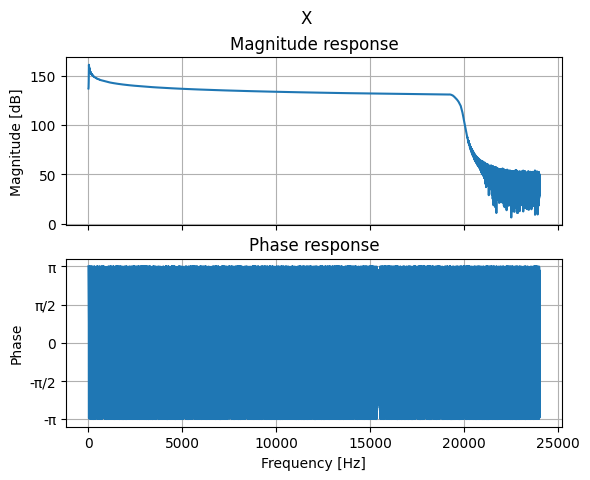

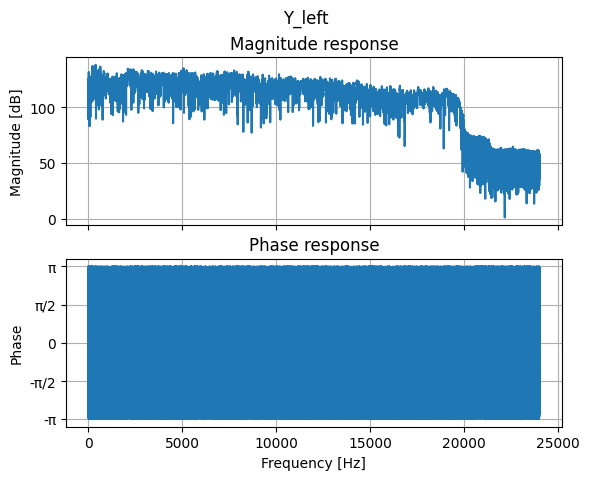

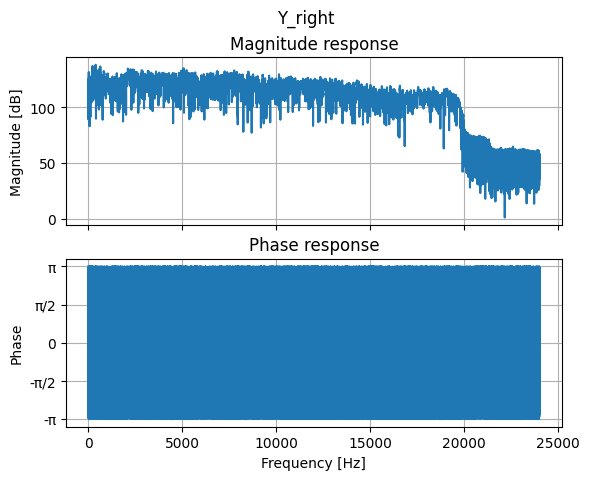

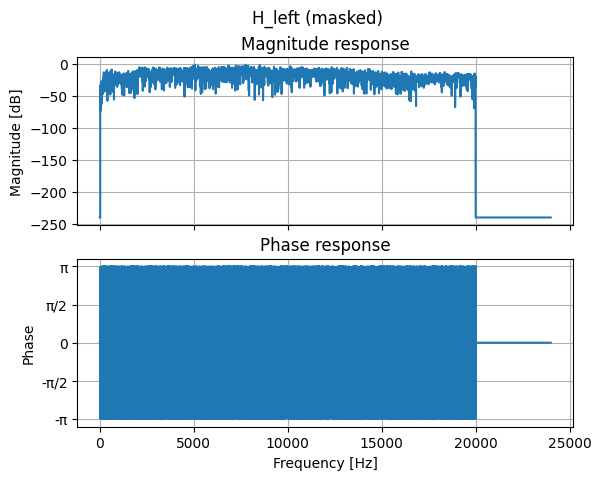

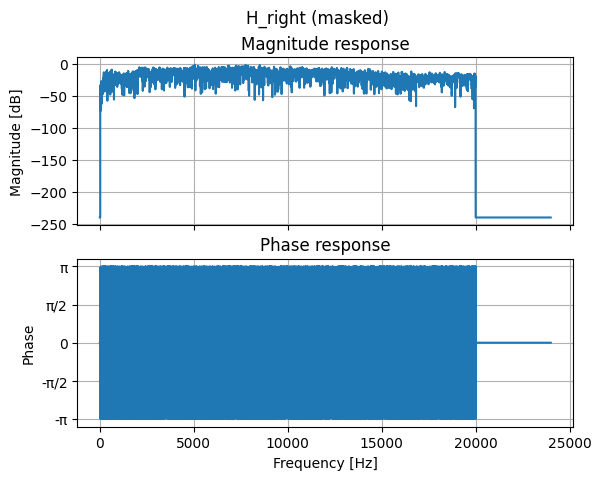

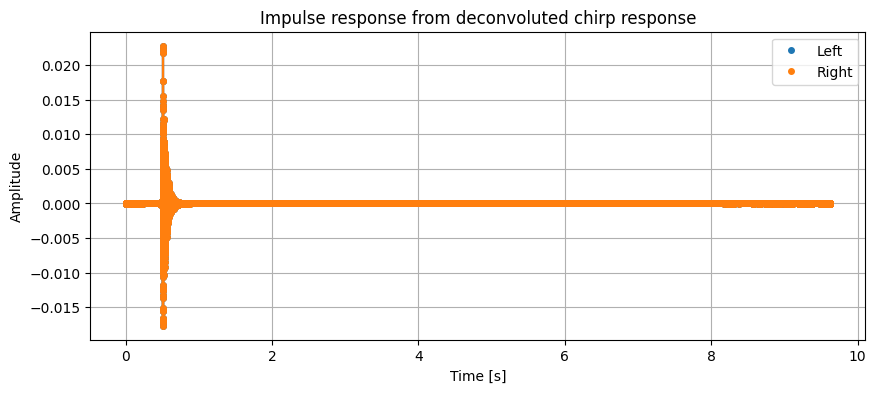

In [8]:
from scipy.io import wavfile
import warnings
from scipy.io.wavfile import WavFileWarning
from scipy.signal.windows import tukey

warnings.filterwarnings("ignore", category=WavFileWarning)

sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

#chirp

fs = sr #abtastrate vom drum-loop, damit alles zusammenpasst
T = 4.0
f0 = 20.0
f1 = 20000.0
A = 0.8 #um sicherzugehen, dass ich clipping vermeide, aber ich musste die lautstärke beim abspielen über meine lautsprecher tatsächlich noch extra senken
fadeTime = 0.02 #um klicks am anfang und ende des chirps zu vermeiden

assert f1 < fs / 2 #sonst entsteht aliasing

n = np.arange(int(T * fs))

#momentanfrequenz wächst exponentiell -> gleich viel zeit pro oktave
fInst = f0 * (f1 / f0) ** (n / (len(n) - 1))

#phase = aufsummierte momentanfrequenz (diskretes integral), wie ein oszillator mit phasenakkumulator
phase = 2 * np.pi * np.cumsum(fInst) / fs
x = A * np.sin(phase)

#tukey-fenster: flach in der mitte, cosinus-flanken von fadeTime am anfang und ende
x *= tukey(len(x), alpha=2 * fadeTime / T)

wavfile.write("chirp_bathroom_20Hz_20kHz.wav", fs, np.int16(x * 32767))

#ich habe mich absichtlich entschieden, den chirp über meine computerlautsprecher abzuspielen und ihn mit einem zoom h5 aufzunehmen, 
#um die auswirkungen von hardware zu sehen, die nicht so gut ist wie die, die wir in tull benutzt haben


#impulsantwort

def get_impulseresponse_from_chirpresponse(og_chirp, recorded_chirp, sr):

    n = len(og_chirp) + len(recorded_chirp) - 1
    
    X = np.fft.rfft(og_chirp, n=n) #fft des originalen mono-chirps
    Y = np.fft.rfft(recorded_chirp, n=n, axis=0) #fft der aufgenommenen stereo-antwort, separat für links und rechts durchgeführt

    #entfaltung
    H = Y / (X[:, None] + 1e-8)

    f = np.fft.rfftfreq(n, 1/sr)

    #nur den frequenzbereich benutzen, der im sweep enthalten ist
    #ohne diese maskierung entstand ein lauter impuls gegen 
    #ende der entfalteten impulsantwort, zusätzlich 
    #zum impuls am anfang
    valid = (f >= 20) & (f <= 20000)

    #frequenzen außerhalb des sweep-bereichs auf null setzen
    H[~valid, :] = 0

    plot_filter_response_from_transfer_function(f, X, "X")
    plot_filter_response_from_transfer_function(f, Y[:, 0], "Y_left")
    plot_filter_response_from_transfer_function(f, Y[:, 1], "Y_right")
    plot_filter_response_from_transfer_function(f, H[:, 0], "H_left (masked)")
    plot_filter_response_from_transfer_function(f, H[:, 1], "H_right (masked)")

    h = np.fft.irfft(H, n=n, axis=0)

    return h


sr_og, og_chirp = wavfile.read("chirp_bathroom_20Hz_20kHz.wav")

sr_chirpresp, chirp_resp = wavfile.read("chirp_bathroom_20Hz_20kHz_response.wav")

sound(og_chirp, sr_og, "Generated chirp")
sound(chirp_resp.T, sr_chirpresp, "Chirp recorded in my bathroom")

# plot_impulse_response("og_chirp", sr_og, og_chirp)
# plot_impulse_response("chirp_resp", sr_chirpresp, chirp_resp)

h = get_impulseresponse_from_chirpresponse(og_chirp, chirp_resp, sr_og)

sound(h[:,1], sr_chirpresp, "Impulse response from deconvoluted chirp")
output = apply_impulse_response(s, h)
sound(output, sr, "Impulse response applied to sound")
plot_impulse_response("Impulse response from deconvoluted chirp response", sr_chirpresp, h)

#der resultierende klang hat definitiv eigenschaften der akustik in meinem badezimmer, 
#klingt aber etwas schärfer, und ich glaube, das liegt daran, dass ich denke, dass die höheren frequenzen
#viel besser erfasst wurden als die tieferen.
#ich bin mir nicht sicher, warum es gegen ende der audiodatei echos der vermischten drums/sweeps gibt, vielleicht wegen der 
#schlechten qualität meiner hardware? oder habe ich etwas falsch berechnet? ich hatte ein ähnliches verhalten auch bei den tull-
#raumantwort-anwendungen unten, aber dort war es nur der sweep selbst, der als echo zu hören war
#gegen ende des resultierenden audios.
#die impulsantwort ist etwas verzögert, ich glaube, das liegt daran, dass ich das aufgenommene audio nicht so zugeschnitten habe,
#dass der sweep am anfang der aufnahme beginnt. 
#abgesehen davon sieht es definitiv wie eine impulsantwort aus.


During the Lab 3 session we collected measurements in Tull [https://www.dropbox.com/scl/fi/cwpfe5bjk0wud68a0x1q8/TullMeasurements_14102026.zip?rlkey=kvgcvukqun6n00ppoomjg167d&st=38hdbg1l&dl=0].  We have balloon pops and sweeps at three different acoustic conditions in the room, as well as some piano being played. Choose two acoustic conditions, and run the same code with that data.  How does it sound?  Does it sound like Tull? Listen to the piano binaural recordings, does it sound like you are moving? 

"Impulse response from deconvoluted chirp, NoCurtainsNoPanels - neumann184",Your browser does not support the audio element.


"Audio filtered with deconvoluted chirp, NoCurtainsNoPanels - neumann184",Your browser does not support the audio element.


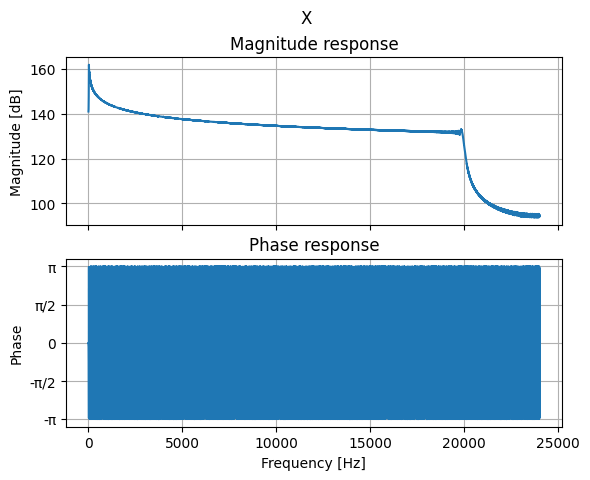

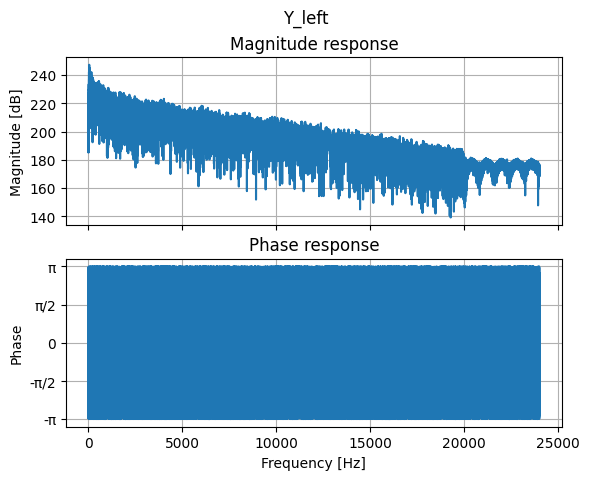

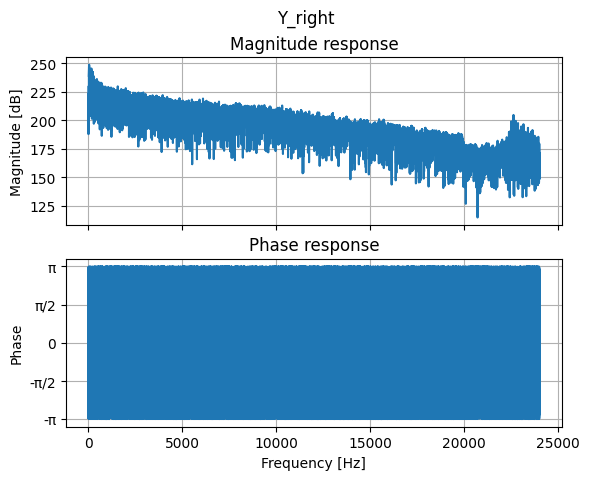

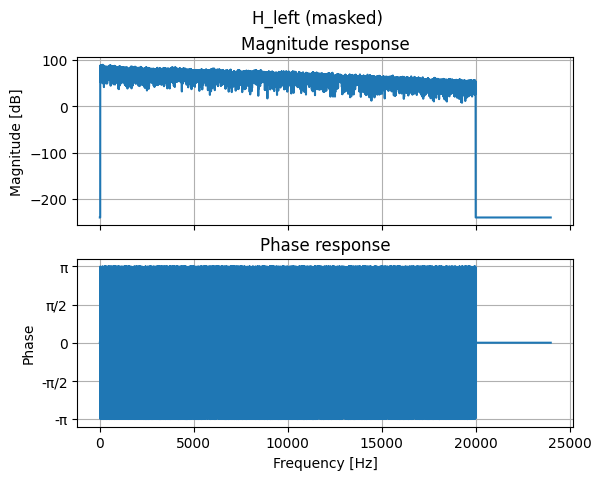

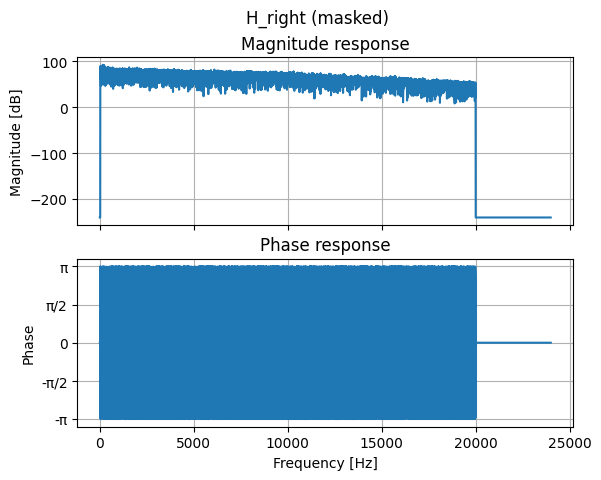

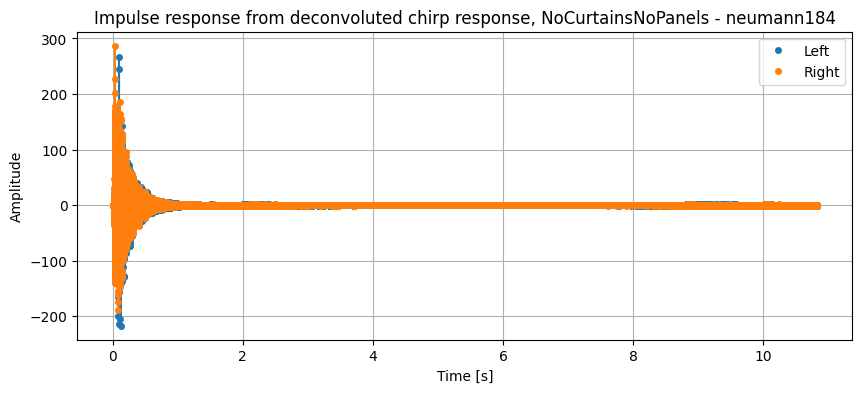

"Impulse response from deconvoluted chirp, NoCurtainsNoPanels - akg414",Your browser does not support the audio element.


"Audio filtered with deconvoluted chirp, NoCurtainsNoPanels - akg414",Your browser does not support the audio element.


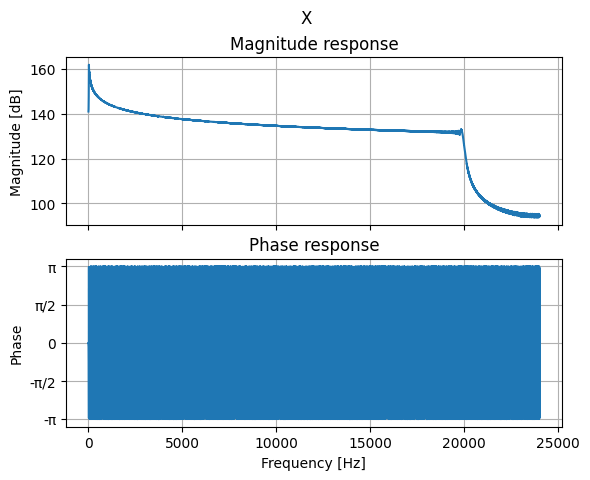

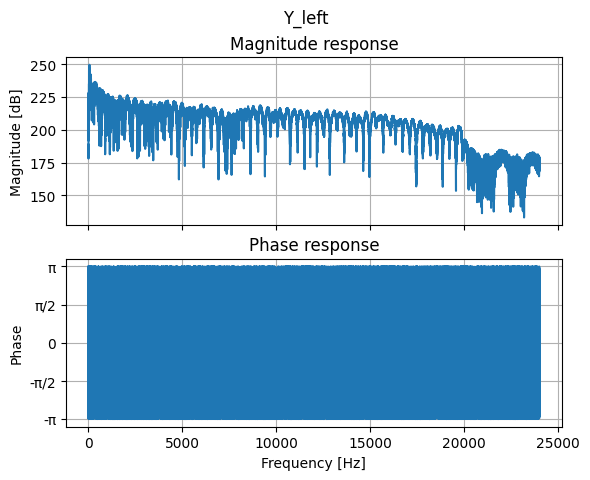

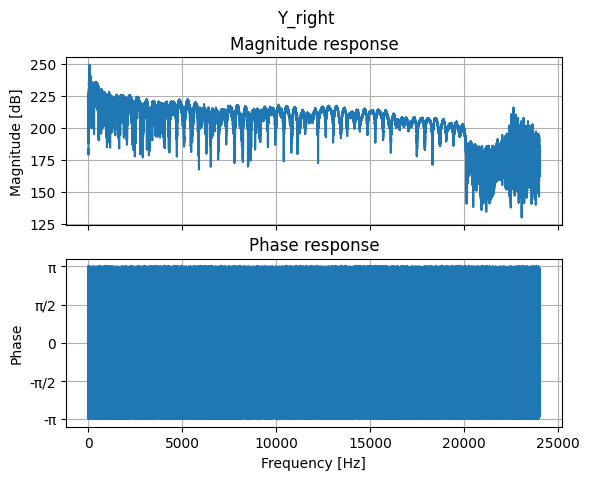

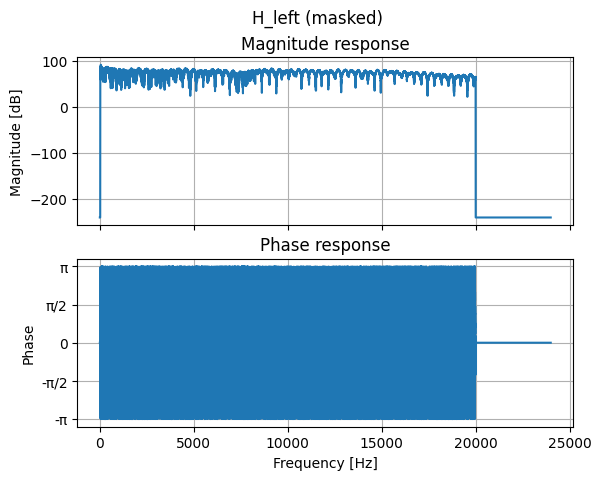

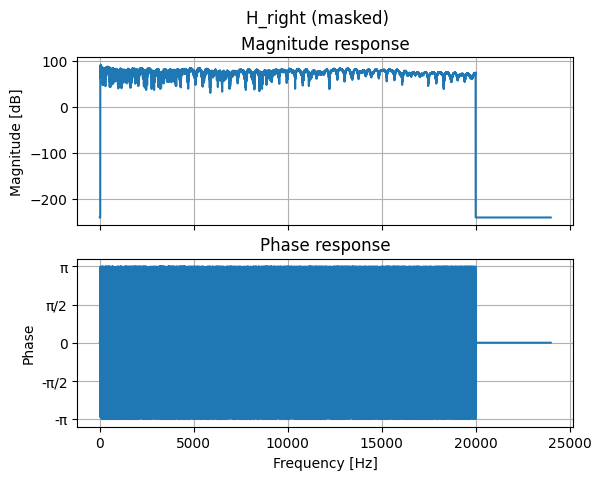

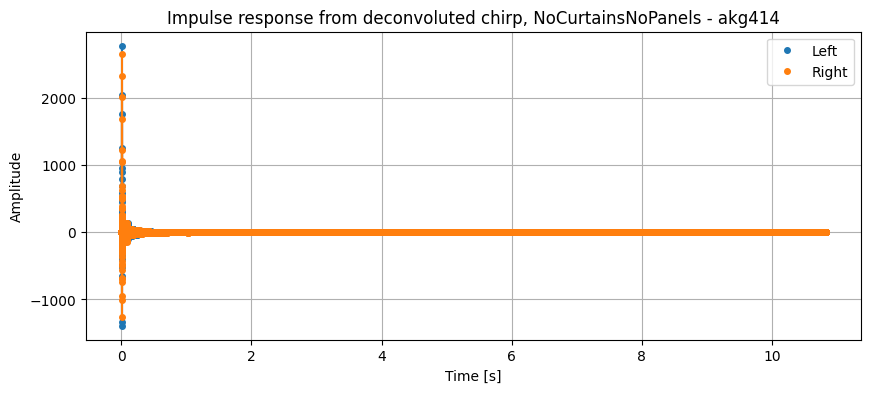

"Impulse response from deconvoluted chirp, YesCurtainsYesPanels - akg414",Your browser does not support the audio element.


"Audio filtered with deconvoluted chirp, YesCurtainsYesPanels - akg414",Your browser does not support the audio element.


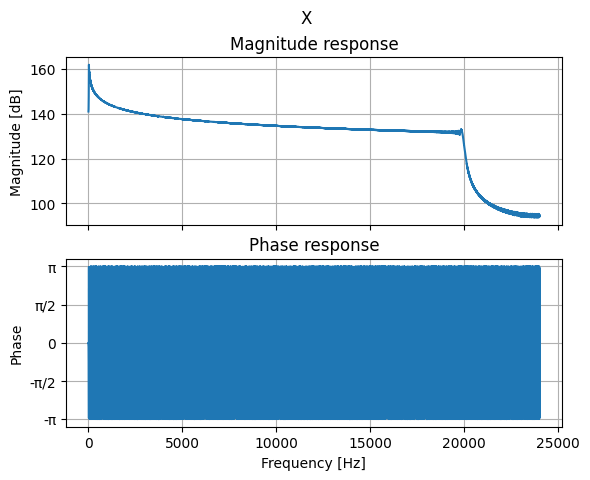

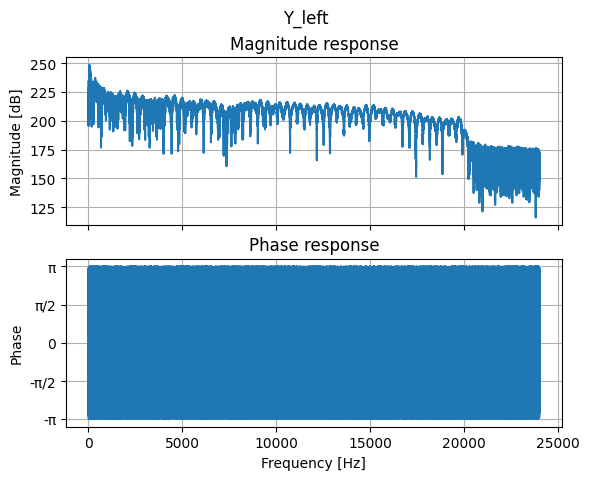

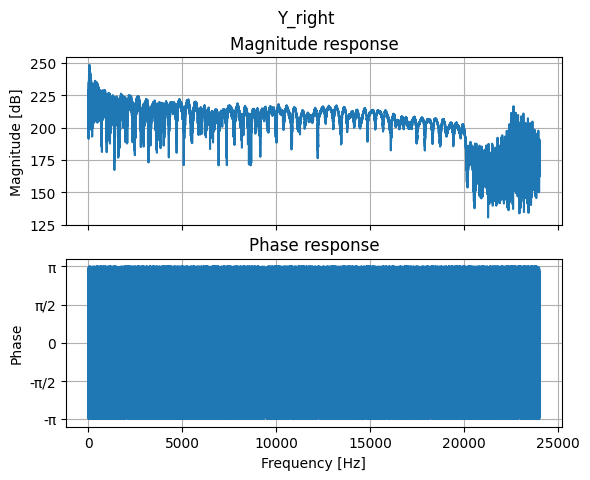

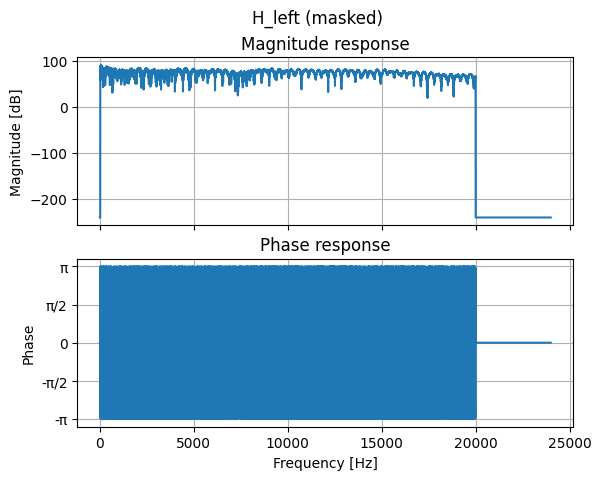

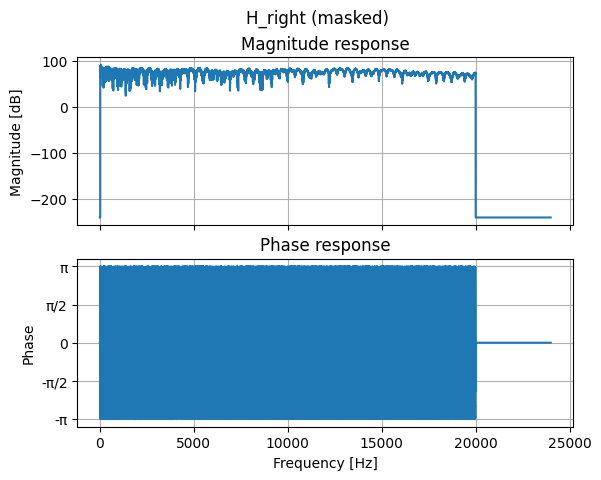

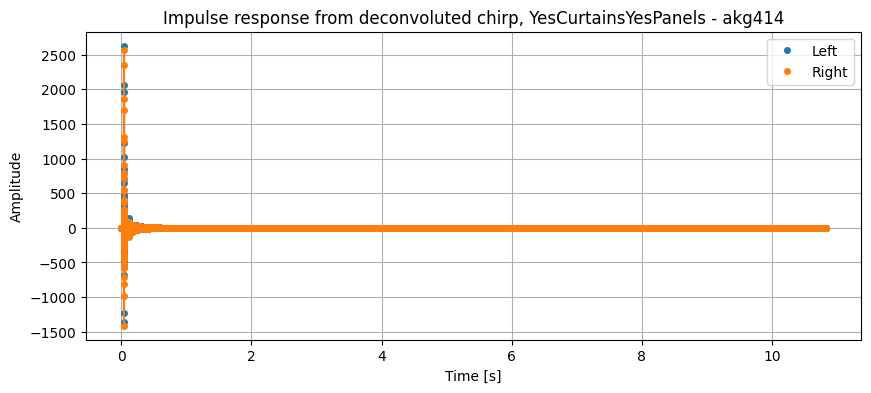

"Audio filtered with balloon pop, NoCurtainsNoPanels - neumannkm184",Your browser does not support the audio element.


"Audio filtered with balloon pop, NoCurtainsNoPanels - akg414",Your browser does not support the audio element.


"Audio filtered with balloon pop, YesCurtainsYesPanels - neumannkm184",Your browser does not support the audio element.


"Audio filtered with balloon pop, YesCurtainsYesPanels - akg414",Your browser does not support the audio element.


In [9]:
import numpy as np

sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

#chirps

sr_og, og_chirp = wavfile.read("TullMeasurements_14102026/sweep_log_20-20k_4s.wav")

sr_chirpresp, chirp_resp = wavfile.read("TullMeasurements_14102026/NoCurtainsNoPanels/sweep2_no-curtains-no-panels_neumannkm184.wav")
# plot_impulse_response("og_chirp", sr_og, og_chirp)
# plot_impulse_response("chirp_resp", sr_chirpresp, chirp_resp)
h = get_impulseresponse_from_chirpresponse(og_chirp, chirp_resp, sr_og)
sound(h[:,1], sr_chirpresp, "Impulse response from deconvoluted chirp, NoCurtainsNoPanels - neumann184")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with deconvoluted chirp, NoCurtainsNoPanels - neumann184")
plot_impulse_response("Impulse response from deconvoluted chirp response, NoCurtainsNoPanels - neumann184", sr_chirpresp, h)

#ich habe es nicht geschafft, die hörbaren sweep-artefakte loszuwerden, die man hört, wenn man das audio der impulsantwort abspielt.
#ich habe versucht:
#- die kanten im frequenzgang nach meiner maskierung zu glätten
#- die zeitpunkte im originalen sweep und im aufgenommenen sweep zu korrelieren
#- den originalen sweep und den aufgenommenen sweep in denselben typ umzuwandeln (sie sind int16 und int 32)
#nichts hat funktioniert... sind diese artefakte ein ergebnis des mikrofons oder der lautsprecher?
#wenn man die impulsantwort auf das audio anwendet, klingt es aber trotzdem gut
#unten ist dasselbe, aber mit der antwort von einem anderen mikrofon (akg), 
#es ist definitiv anders, hat aber immer noch einige artefakte

sr_chirpresp, chirp_resp = wavfile.read("TullMeasurements_14102026/NoCurtainsNoPanels/sweep1_no-curtains-no-panels_akg414.wav")
# plot_impulse_response("og_chirp", sr_og, og_chirp)
# plot_impulse_response("chirp_resp", sr_chirpresp, chirp_resp)
h = get_impulseresponse_from_chirpresponse(og_chirp, chirp_resp, sr_og)
sound(h[:,1], sr_chirpresp, "Impulse response from deconvoluted chirp, NoCurtainsNoPanels - akg414")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with deconvoluted chirp, NoCurtainsNoPanels - akg414")
plot_impulse_response("Impulse response from deconvoluted chirp, NoCurtainsNoPanels - akg414", sr_chirpresp, h)

#der nächste ist immer noch mit akg, aber mit vorhängen und paneelen

sr_chirpresp, chirp_resp = wavfile.read("TullMeasurements_14102026/YesCurtainsYesPanels/sweep2_yes-curtains-yes-panels_akg414.wav")
# plot_impulse_response("og_chirp", sr_og, og_chirp)
# plot_impulse_response("chirp_resp", sr_chirpresp, chirp_resp)
h = get_impulseresponse_from_chirpresponse(og_chirp, chirp_resp, sr_og)
sound(h[:,1], sr_chirpresp, "Impulse response from deconvoluted chirp, YesCurtainsYesPanels - akg414")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with deconvoluted chirp, YesCurtainsYesPanels - akg414")
plot_impulse_response("Impulse response from deconvoluted chirp, YesCurtainsYesPanels - akg414", sr_chirpresp, h)







#ballonplatzer

sr_ir, h = wavfile.read("TullMeasurements_14102026/NoCurtainsNoPanels/balloon-center_no-curtains-no-panels_neumannkm184.wav")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with balloon pop, NoCurtainsNoPanels - neumannkm184")

sr_ir, h = wavfile.read("TullMeasurements_14102026/NoCurtainsNoPanels/balloon-side_no-curtains-no-panels_akg414.wav")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with balloon pop, NoCurtainsNoPanels - akg414")




sr_ir, h = wavfile.read("TullMeasurements_14102026/YesCurtainsYesPanels/balloon-right_yes-curtains-yes-panels_neumannkm184.wav")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with balloon pop, YesCurtainsYesPanels - neumannkm184")

sr_ir, h = wavfile.read("TullMeasurements_14102026/YesCurtainsYesPanels/balloon-right_yes-curtains-yes-panels_akg414.wav")
output = apply_impulse_response(s, h)
sound(output, sr, "Audio filtered with balloon pop, YesCurtainsYesPanels - akg414")


#ich finde, jedes beispiel oben klingt wie tull, aber sie haben leicht unterschiedliche qualitäten, 
#und das resultierende audio, das mit den entfalteten chirps gefiltert wurde, hat einige sweep-artefakte, nachdem das drum-
#audio aufgehört hat, von denen ich nicht weiß, wie ich sie loswerden kann.
#ich finde, das akg414 klingt besser als das neumann km184, weil es nicht so viele 
#dieser sweep-artefakte hat. das akg klingt auch näher, vielleicht lag das nur an der mikrofonposition?
#ich finde, der unterschied zwischen vorhängen/paneelen und keinen vorhängen/paneelen ist definitiv hörbar.
#die entfalteten sweeps schaffen es, im resultierenden audio einen volleren klang zu erzielen als die ballonplatzer. 
#das mit den ballonplatzern gefilterte audio klingt im vergleich etwas entfernt und hohl.


## Part 5. 

Now let's move to 3D sounds.  For this lab we will focus on models that work with headphones. We will make use of simple filters and HRTFs to create static and moving sources. Use the this sound [https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1 ] for all the sound examples.

### Part i: Static sources using ITD/ILD cues

Assume the following source locations: 

- Straight ahead

- 45 degrees to the left

- 80 degrees to the right

- 160 degrees to the left

For each location find the source’s delay between the two ears (assume a source distance of 2 meters), and design two filters that will simulate that ITD and ILD features (feel free to round the IDT delays to an integer sample size). Assume that when sounds come from the side of the head the attenuation at the contralateral ear is by a factor of 0.7. From sounds coming medial plane (between the ears) there will be no attenuation due to the head. For positions moving from the medial plane towards the sides you can interpolate between no attenuation and a factor of 0.7. Design and plot the filters that correspond to the locations shown above and use them to spatialize the test sound.  Try it with other sounds too if you like.

Listen to the result through headphones and verify that it sounds somewhat localized (it won’t sound perfect, but it should be believable).

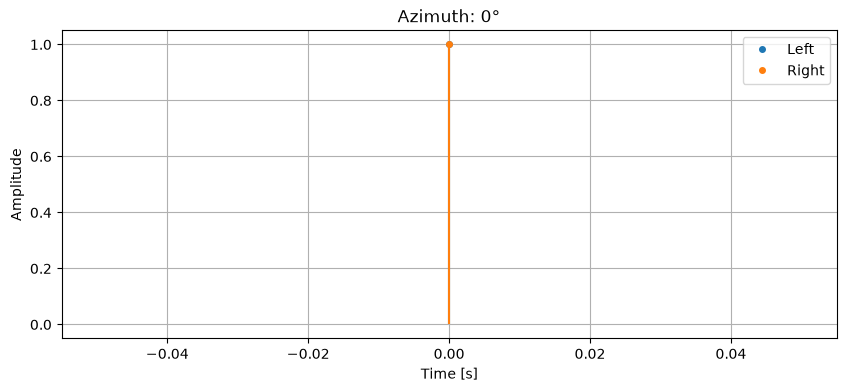

Azimuth: 0°,Your browser does not support the audio element.


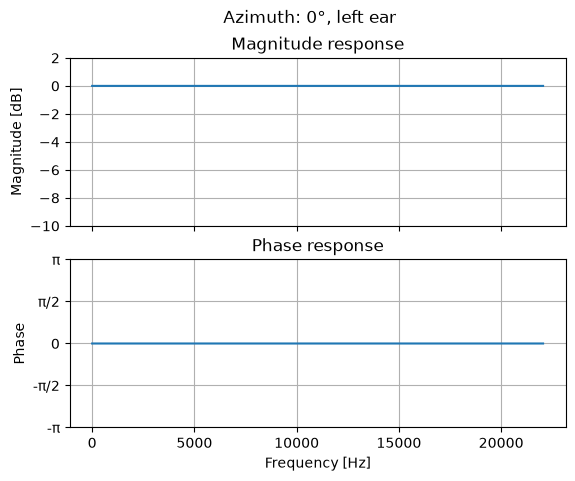

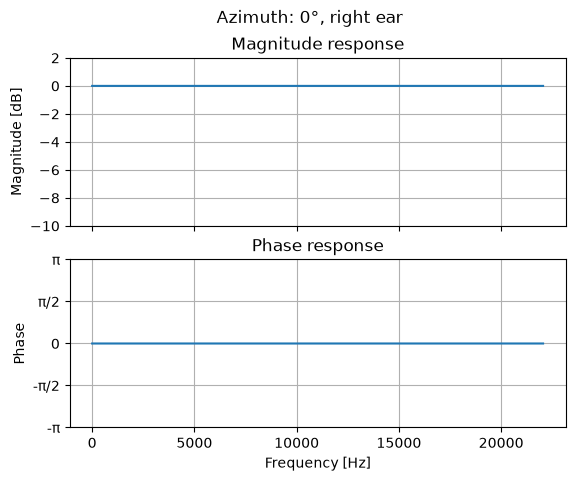

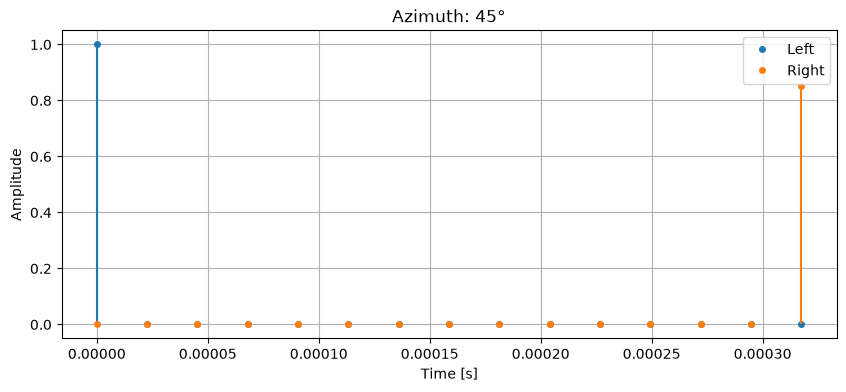

Azimuth: 45°,Your browser does not support the audio element.


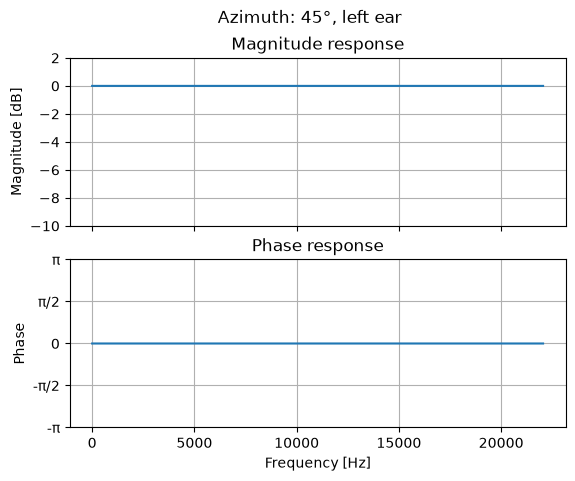

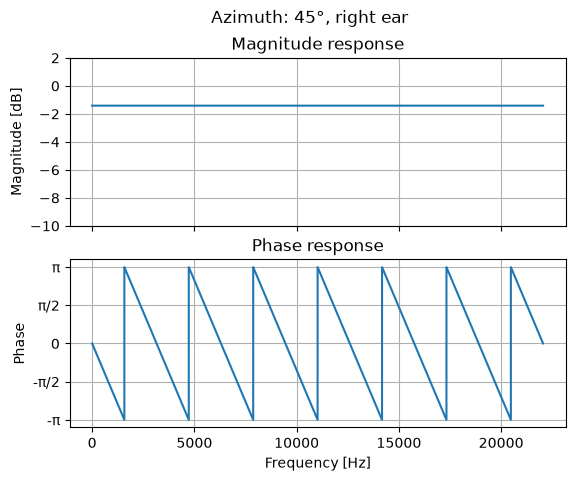

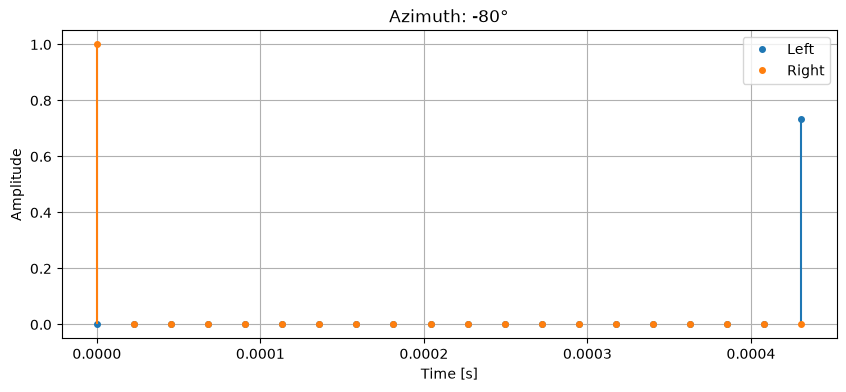

Azimuth: -80°,Your browser does not support the audio element.


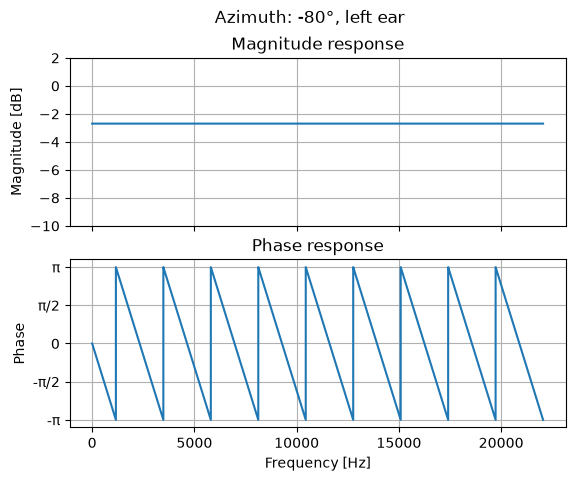

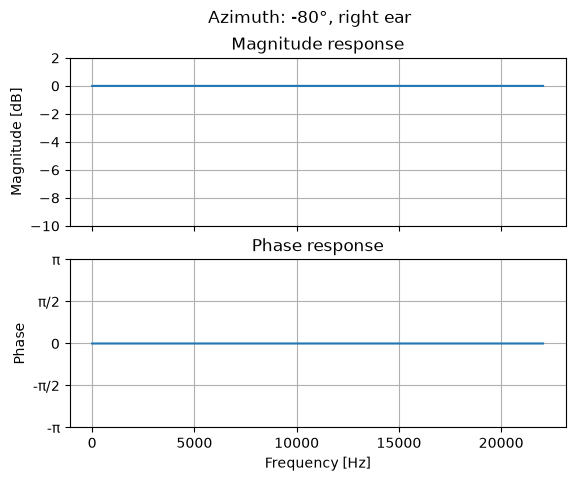

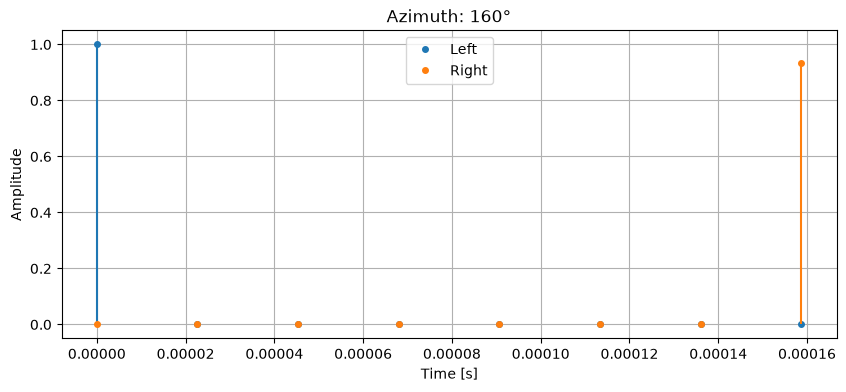

Azimuth: 160°,Your browser does not support the audio element.


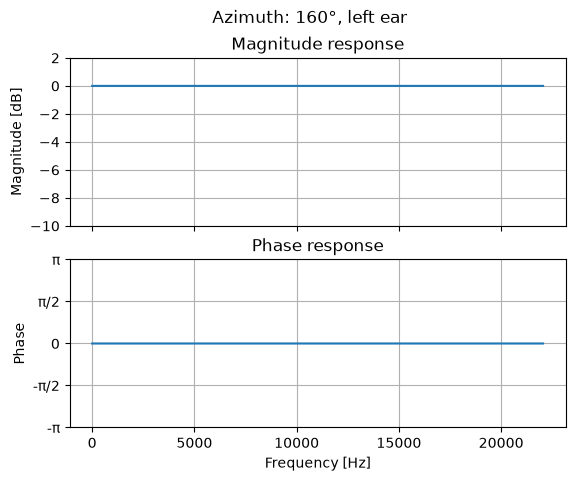

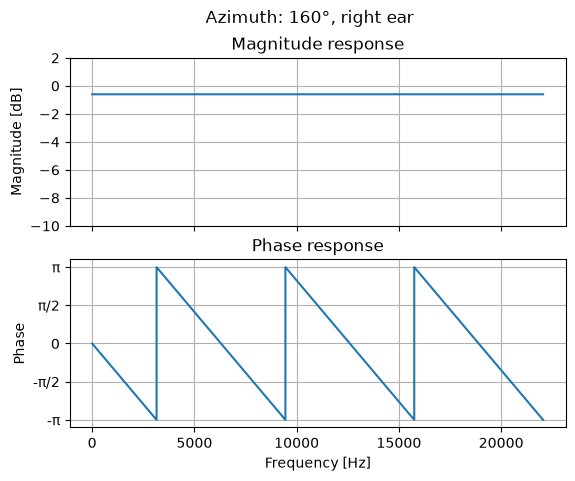

In [12]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')

def make_ilt_itd_filter(angle, sr, source_distance=2, ear_distance=0.15, c=343):
    #argumente
    #winkel:
    #0°   = vorne
    #90°  = links
    #180° = hinten
    #270° = rechts
    #360° = vorne
    #~15 cm zwischen den ohren, schallgeschwindigkeit in m/s

    angle = angle % 360
    theta = np.deg2rad(angle)

    #position der quelle (kopf schaut in richtung 0° und links ist gegen den uhrzeigersinn)
    source_x = -source_distance * np.sin(theta)
    source_y = source_distance * np.cos(theta)

    #abstand zu jedem ohr
    #kopf ist im ursprung zentriert
    #linkes ohr  = (-ear_distance/2, 0)
    #rechtes ohr = (+ear_distance/2, 0)
    d_left = np.sqrt((source_x + ear_distance/2)**2 + source_y**2)
    d_right = np.sqrt((source_x - ear_distance/2)**2 + source_y**2)

    #zeit, bis der schall jedes ohr erreicht
    t_left = d_left / c
    t_right = d_right / c

    #vorzeichenbehaftete itd in sekunden
    #negative itd: linkes ohr empfängt den schall zuerst 
    #positive itd: rechtes ohr empfängt den schall zuerst
    itd = t_left - t_right 

    #vorzeichenbehaftete verzögerung in samples
    delay = int(round(itd * sr))

    #vorzeichenbehaftete verzögerung in getrennte ohrverzögerungen umwandeln
    delay_left = max(delay, 0)
    delay_right = max(-delay, 0)

    #abschwächungen für die ild
    attenuation = np.interp(angle, [0, 90, 180, 270, 360], [1.0, 0.7, 1.0, 0.7, 1.0])

    #länge der filter
    h_left = np.zeros(abs(delay) + 1)
    h_right = np.zeros(abs(delay) + 1)

    #vorzeichen für die arithmetische berechnung der verstärkung unten
    sign = np.sign(delay)

    #abgeschwächte verzögerungen
    #positives vorzeichen bedeutet, dass das linke ohr weiter weg ist, also das linke ohr abschwächen
    #negatives vorzeichen bedeutet, dass das rechte ohr weiter weg ist, also das rechte ohr abschwächen
    #vorzeichen = 0 bedeutet keinen unterschied in der abschwächung zwischen den ohren
    h_left[delay_left] = 1 - max(sign, 0) * (1 - attenuation)
    h_right[delay_right] = 1 - max(-sign, 0) * (1 - attenuation)

    return h_left, h_right



angles = [0, 45, -80, 160]

for angle in angles:

    h_left, h_right = make_ilt_itd_filter(angle, sr)

    plot_impulse_response(f"Azimuth: {angle}°", sr, np.column_stack((h_left, h_right)))
    plot_filter_response(f"Azimuth: {angle}°, left ear", sr, h_left, auto_scale=False, min_db=-10, max_db=2)
    plot_filter_response(f"Azimuth: {angle}°, right ear", sr, h_right, auto_scale=False, min_db=-10, max_db=2)

    y_left = np.convolve(s, h_left)
    y_right = np.convolve(s, h_right)

    y = np.array([y_left, y_right])

    sound(y, sr, f"Azimuth: {angle}°")



### Part ii: Static sources using HRTFs

Download the HTTF archive from [https://www.dropbox.com/scl/fi/rk9vy4axcazrhxhkudrxy/compact.zip?rlkey=2mvuy2sa3zxcbzjtsiaf677gp&dl=1 ]. Below you will also find code for the function load_hrtf which returns the left and right HRTF filters given as input a source’s azimuth and elevation. These filters will be much better than the ITD/ILD filters for localizing sounds.

Apply the HRTFs on the given test sound and create 3D sounds that correspond to the locations given above. You will need to convolve with the left and right HRTF of the desired position and generate two sounds, one for each channel. Verify that they sound correct using headphones; are they better than before? What differences do you observe? When you use these make sure that the sample rates of the HRTFs and the sound you convolve them with match.  The HRTFs are sampled at 44.1kHz. As usual make sure you make some plots to make sure that filters look ok.

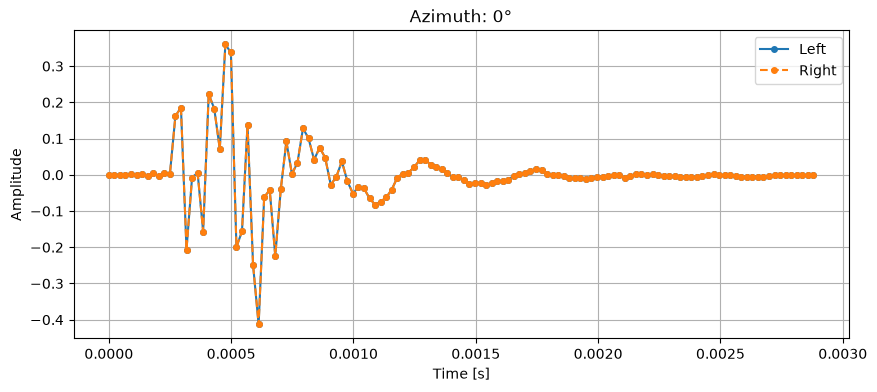

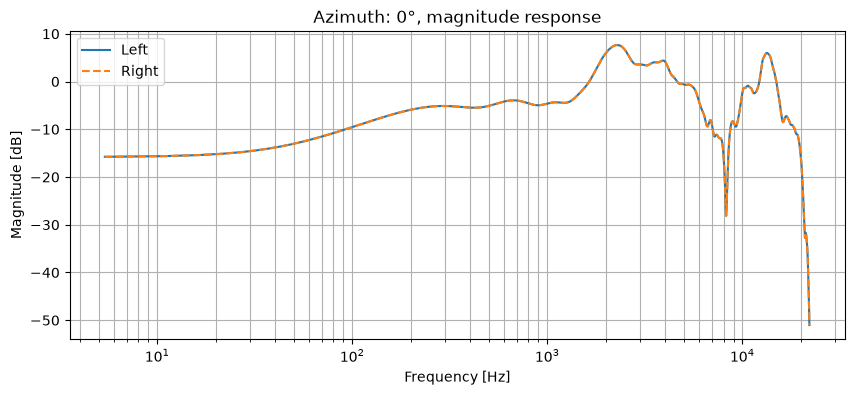

Azimuth: 0°  hrtf: itd = 0 samples, ild = 0.0 dB  |  itd/ild model: itd = 0 samples, ild = 0.0 dB


Azimuth: 0°,Your browser does not support the audio element.


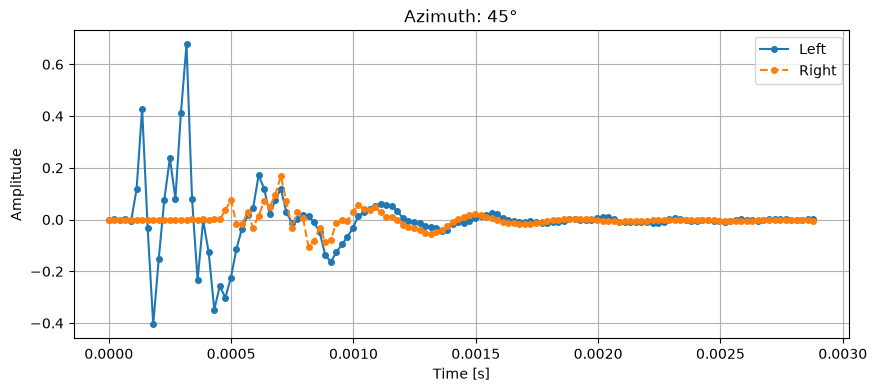

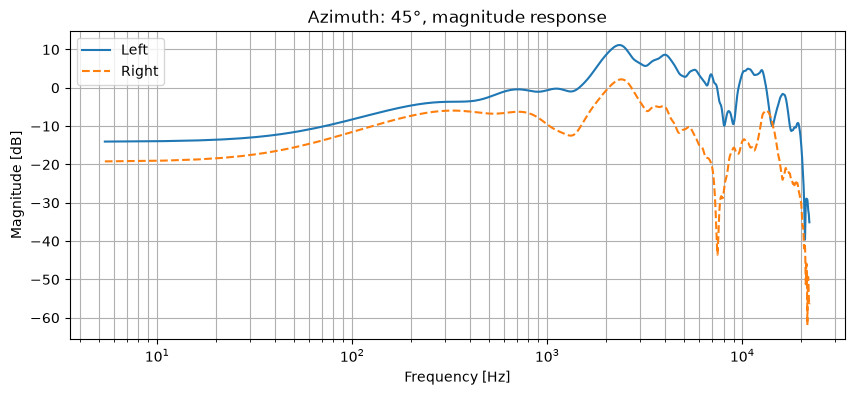

Azimuth: 45°  hrtf: itd = -17 samples, ild = 11.3 dB  |  itd/ild model: itd = -14 samples, ild = 1.4 dB


Azimuth: 45°,Your browser does not support the audio element.


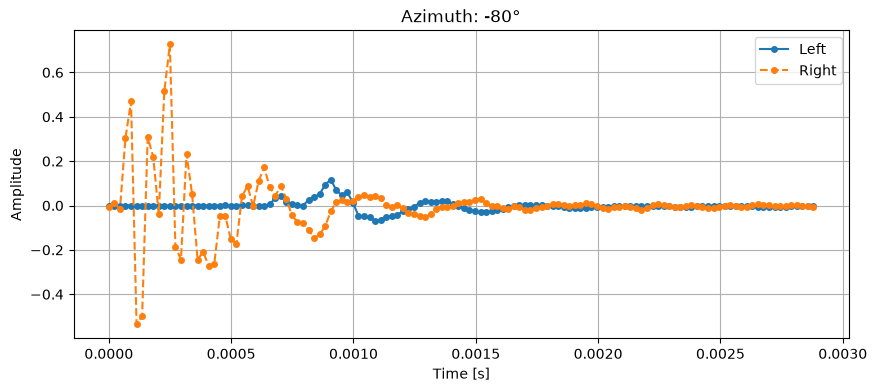

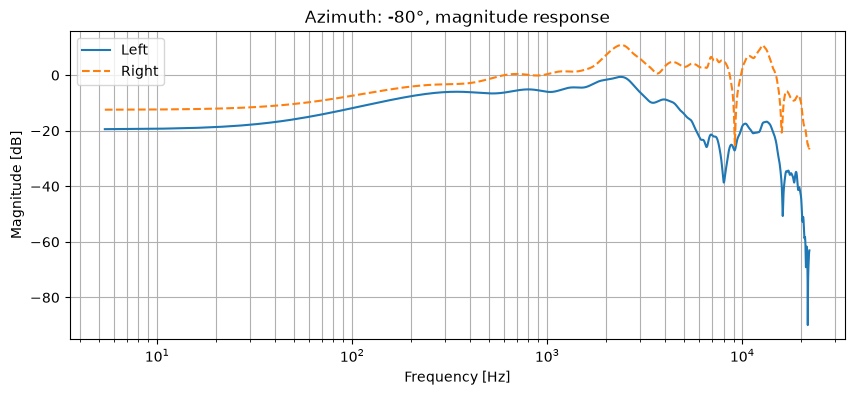

Azimuth: -80°  hrtf: itd = 29 samples, ild = -15.2 dB  |  itd/ild model: itd = 19 samples, ild = -2.7 dB


Azimuth: -80°,Your browser does not support the audio element.


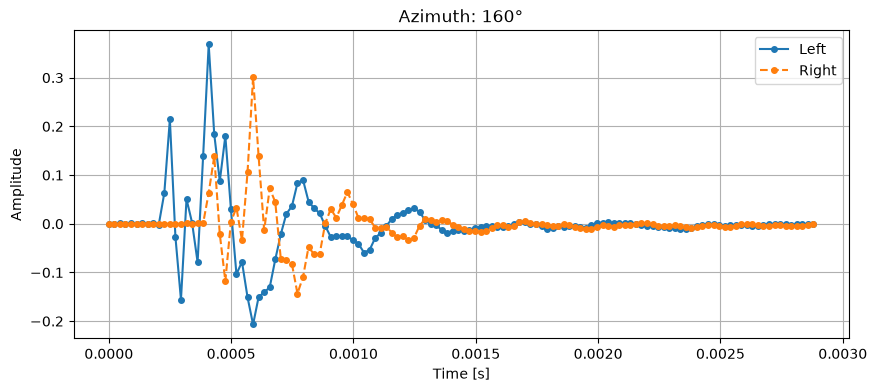

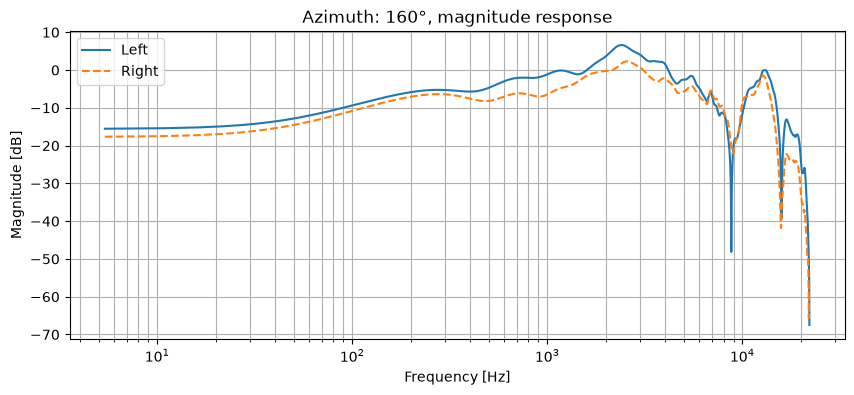

Azimuth: 160°  hrtf: itd = -8 samples, ild = 3.1 dB  |  itd/ild model: itd = -7 samples, ild = 0.6 dB


Azimuth: 160°,Your browser does not support the audio element.


In [13]:
def load_hrtf( ad, ed):
    # Return the HRTFs for a given azimuth and elevation
    #  function h,a,e = load_hrtf( ad, ed)
    #
    # Inputs:
    #   ad  is the azimuth to use in degrees (0 is front)
    #   ed  is the elevation to use in degrees (0 is level with ears)
    #
    # Output:
    #   l,r two 128pt arrays, first is left ear HRTF, second is right ear HRTF
    from numpy import remainder, fromfile

    # Path where the HRTFs are
    p = './compact/'

    # Get nearest available elevation
    e = max( -40, min( 90, 10*(ed//10)))

    # Get nearest available azimuth
    ad = remainder( ad, 360)
    if ad > 180:
        ad = ad-360
    if ad < 0:
        a = abs( ad)
        fl = 1
    else:
        a = ad
        fl = 0
    a = max( 0, min( 180, 5*(a//5)))

    # Load appropriate response
    h = fromfile( '%s/elev%d/H%de%.3da.dat' % (p, e, e, a), dtype='>i2').astype( 'double')/32768
    if fl:
        return h[1::2],h[::2]
    else:
        return h[::2],h[1::2]


sr, s = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')
angles = [0, 45, -80, 160] #angepasst, damit die richtung zur vorherigen aufgabe passt
ed = 0

for angle in angles:
    ad = -angle #load_hrtf zählt positiv nach rechts, hier ist positiv links wie in teil i
    h_left, h_right = load_hrtf(ad, ed)
    plot_impulse_response(f"Azimuth: {angle}°", sr, np.column_stack((h_left, h_right)), style="line")

    #beide ohren in einem plot mit log-frequenzachse, so sieht man die ild direkt
    f, H_left = signal.freqz(h_left, worN=2**12, fs=sr)
    _, H_right = signal.freqz(h_right, worN=2**12, fs=sr)
    plt.figure(figsize=(10, 4))
    plt.semilogx(f[1:], 20 * np.log10(np.abs(H_left[1:]) + 1e-12), label="Left")
    plt.semilogx(f[1:], 20 * np.log10(np.abs(H_right[1:]) + 1e-12), "--", label="Right")
    plt.title(f"Azimuth: {angle}°, magnitude response")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Magnitude [dB]")
    plt.legend()
    plt.grid(True, which="both")
    plt.show()

    #itd und ild aus den hrtfs messen und mit dem modell aus teil i vergleichen
    #positive itd: das linke ohr hört den klang später
    itd = np.argmax(np.correlate(h_left, h_right, "full")) - (len(h_right) - 1)
    ild = 10 * np.log10(np.sum(h_left**2) / np.sum(h_right**2))

    m_left, m_right = make_ilt_itd_filter(angle, sr)
    itd_model = np.argmax(np.abs(m_left)) - np.argmax(np.abs(m_right))
    ild_model = 20 * np.log10(np.max(np.abs(m_left)) / np.max(np.abs(m_right)))

    print(f"Azimuth: {angle}°  hrtf: itd = {itd} samples, ild = {ild:.1f} dB  |  "
          f"itd/ild model: itd = {itd_model} samples, ild = {ild_model:.1f} dB")

    y_left = np.convolve(s, h_left)
    y_right = np.convolve(s, h_right)

    y = np.array([y_left, y_right])
    
    sound(y, sr, f"Azimuth: {angle}°")


#ich finde, man hört sehr deutlich, dass die hrtfs einen genaueren frequenzgang haben als die ild/itd-version.
#ich finde, das ist auch aus den plots ziemlich offensichtlich... natürlich hat das bewegen der quellposition um den 
#kopf nicht für alle frequenzen genau dieselbe amplitude!
#es klingt generell realistischer. der klang aus 160° klingt auch etwas mehr so, als ob er 
#tatsächlich von hinten kommt, ich glaube nicht, dass die ild/itd damit überhaupt erfolgreich war, was sinn ergibt, weil 
#es im obigen itd/ild-modell eigentlich keinen unterschied zwischen klängen von vorne und von hinten gibt.
    

### Part iii: Dynamic sources with HRTFs

In this part you will need to make a moving sound source. In order to do so we will make use of a fast convolution routine based on your STFT code from lab 1 (ha, you thought you were done with that!). In order to perform fast convolution we can perform an STFT of the sound to use, multiply each time frame of this transform with the DFT of the filter that we want  to impose and then use overlap add to transform back to the time domain.

Start by taking each sound from above, and apply your STFT on it. Make sure that the size of the transform is the same as the HRTF’s filter length. The hop size should be the same as the DFT size and you will need to zero pad each frame by as much as the DFT size in order to facilitate the tail of the convolution. Do not use an analysis/synthesis window.

Once you compute this STFT, go through its every time frame and element-wise multiply it with the desired HRTF filter to generate the STFT of the left and right sounds. Figure out which HRTF angle to multiply each frame with so that by the end of the sound you will have made it go around your head.

Once you perform these operations you will have generated two STFT matrices, one for the left channel and one for the right. Use your inverse STFT routine and play the stereo sound through your headphones. You should hear a convincing rendering of the original sounds circling around your head.

Render the sounds so that we can listen to them too.

In [14]:
#stft und inverse stft

def stft(input_sound, frame_size, hop_size, window=None, pad=0):
    #input_sound ist ein 1d-array, das einen eingangsklang enthält.
    #frame_size ist die anzahl der samples in jedem analyse-frame.
    #hop_size ist die anzahl der samples, um die dein analyse-frame weiterrückt.
    #window ist ein vektor, der das analysefenster enthält, das du benutzen wirst.

    if window is None:
        window = np.ones(frame_size)

    #eingangsklang auffüllen, damit wir nur volle frames bekommen
    remainder = (len(input_sound) - frame_size) % hop_size #für volle fenster bei jedem hop muss input_sound frame_size+n*hop_size lang sein
    padding = (hop_size - remainder) % hop_size #(kein auffüllen, wenn der rest ein sauberer zusätzlicher hop_size ist)
    input_sound = np.pad(input_sound, (0, padding))

    frames = np.lib.stride_tricks.sliding_window_view(input_sound, frame_size)[::hop_size] #array mit überlappenden/nicht überlappenden frames der länge frame_size erzeugen, hop_size voneinander entfernt
    windowed_frames = frames * window

    #zusätzliche nullen an jedem frame, damit der faltungsschweif platz hat
    if pad:
        windowed_frames = np.pad(windowed_frames, ((0, 0), (0, pad)))

    f = np.fft.rfft(windowed_frames).T

    #ein komplexwertiges spektrogramm zurückgeben (frequenzen x zeit)
    return f


def istft(stft_output, frame_size, hop_size, window=None, pad=0):
    fft_size = frame_size + pad

    if window is None:
        window = np.ones(fft_size)

    #ausgangsarray mit der richtigen länge erzeugen
    num_frames = stft_output.shape[1]
    output_length = fft_size + (num_frames - 1) * hop_size
    output = np.zeros(output_length)

    #jedes spektrum (spalte) zurück in einen frame im zeitbereich umwandeln
    frames = np.fft.irfft(stft_output, n=fft_size, axis=0).T

    windowed_frames = frames * window

    #spalte mit dem startsample jedes frames
    start_indices = np.arange(num_frames) * hop_size

    #zeilen mit den indizes, wo jedes sample addiert werden soll
    add_at_indices = start_indices[:, None] + np.arange(fft_size)

    #overlap-add
    np.add.at(output, add_at_indices.ravel(), windowed_frames.ravel())

    return output



sr_crunch, crunch = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')
sr_drums, drums = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

#der drum-loop hat 48 khz, die hrtfs sind mit 44.1 khz gemessen, also erst umrechnen
drums = signal.resample_poly(drums, 147, 160)
sr_drums = 44100


def apply_hrtf_sweep(audio, frame_size, transform_size):
    #zero-padding, das nötig ist, damit jeder audio-frame transform_size samples lang ist
    pad = transform_size - frame_size

    #hop_size gleich frame_size für schnelle faltung
    hop_size = frame_size

    f_audio = stft(audio, frame_size, hop_size, pad=pad)
    num_frames = f_audio.shape[1]

    angles = np.arange(0, 360, 5) #ein filter alle 5 grad, horizontale ebene
    ed = 0

    #ein winkelindex pro stft-spalte (winkel können sich wiederholen)
    frame_angles = (np.arange(num_frames) * len(angles) / num_frames).astype(int)

    H_left = []
    H_right = []

    #jede hrtf in ein spektrum umwandeln, das mit einer stft-spalte übereinstimmt, 
    #mit derselben transformationsgröße wie die stft
    for ad in angles:
        h_left, h_right = load_hrtf(ad, ed) #hrtfs im zeitbereich 

        #hrtfs auf dieselbe transformationsgröße wie die audio-frames auffüllen
        h_left = np.pad(h_left, (0, transform_size - len(h_left)))
        h_right = np.pad(h_right, (0, transform_size - len(h_right)))

        H_left.append(np.fft.rfft(h_left))
        H_right.append(np.fft.rfft(h_right))

    #winkel x frequenz
    H_left = np.array(H_left)   
    H_right = np.array(H_right)

    #jede stft-spalte filtern
    f_left = H_left[frame_angles].T * f_audio
    f_right = H_right[frame_angles].T * f_audio

    #overlap-add, in den zeitbereich
    left = istft(f_left, frame_size, hop_size, pad=pad)
    right = istft(f_right, frame_size, hop_size, pad=pad)

    stereo = np.array([left, right])

    return stereo


#dft-größe = hrtf-länge (128), jeder frame wird um die dft-größe mit nullen aufgefüllt
frame_size = 128
transform_size = 256

crunch_sweep = apply_hrtf_sweep(crunch, frame_size, transform_size)
sound(crunch_sweep, sr_crunch, "Crunch moving around the head")

drums_sweep = apply_hrtf_sweep(drums, frame_size, transform_size)
sound(drums_sweep, sr_drums, "Drums moving around the head")


Crunch moving around the head,Your browser does not support the audio element.


Drums moving around the head,Your browser does not support the audio element.
